# Banning five path algorithms in one prompt: runnable demo

**Artifact `art_IVZc3TWCeE9f` (experiment).** What does **Qwen3-8B** (thinking off, vLLM 0.11, temperature 1.0) write
when one prompt bans four or five of its usual grid path-search algorithms? The study samples 100 programs per condition
(5 ban templates x 20), labels every program by its **mechanism** (runtime tracer + AST rules + a blind LLM judge), hash-commits
likelihood-based landing forecasts *before* sampling the multi-name bans, and then reads the result in activation space.

Full-run headline (task T1 = "find a path in a grid", N = 100 programs per condition):

| condition | banned | landing (mechanism of the written program) | avoidance (Wilson 95%) |
|---|---|---|---|
| baseline | none | BFS 100 | n/a |
| single ban | BFS | DFS 86, BFS 14 | 0.86 (0.78-0.91) |
| TOP | BFS, DFS, greedy, IDDFS | BFS 59, DFS 26, greedy 2, other 13 | 0.13 (0.08-0.21) |
| ARC | BFS, BiBFS, A*, greedy | BFS 63, DFS 37 | 0.37 (0.28-0.47) |
| SCATTER | BFS, DFS, greedy, IDA* | BFS 69, DFS 27, A* 2, other 2 | 0.04 (0.02-0.10) |
| TOP5 | BFS, DFS, greedy, IDDFS, A* | BFS 63, DFS 36, IDDFS 1 | 0.00 (0.00-0.04) |

A single ban works. Every list ban fails its gate (avoidance >= 0.5): the model re-implements the banned BFS or DFS, and
41-92% of those programs never name their own mechanism (DFS becomes "backtracking").

**What runs here.** `method.py` is an orchestrator with one sub-command per stage. Sampling (vLLM), teacher-forced
scoring (HF on a GPU) and the judge (OpenRouter) cannot run in Colab, so their saved outputs are loaded. Everything
downstream runs on CPU with the original code, on 100 curated T1 programs (`mini_demo_data.json`: 45 forced programs of
the 7 analysis algorithms, plus 55 programs written under the baseline, the single ban and the four multi-bans).

| section | original file(s) | what runs |
|---|---|---|
| 1 | `common.py` | frozen protocol constants and helpers |
| 2 | (new) | demo data written into the folder layout the stages read; stand-in for the activation loader |
| 3 | `method.py` | the stage dispatcher `main()` |
| 4 | `labeller_ext/extract.py`, `ast_rules.py`, `combine.py` | S3 mechanism labels: extraction, AST rules, combine rule |
| 5 | `mb/sets.py` | S6 geodesic geometry and TOP / ARC / SCATTER set selection |
| 6 | `mb/forecasts.py`, `common.verify_chain` | S7 FRLP landing forecasts and the sha256 commitment chain |
| 7 | `analysis/landing.py` | S10 landing, avoidance, disguise and landing tests via `main(["landing"])` |
| 8 | `analysis/manifold.py` | S11 activation-space manifold, MDS, Isomap and persistence via `main(["manifold"])` |
| 9 | (new) | results: demo subset next to the full run |

Lines marked `# DEMO:` are the only changes to the original code.

In [1]:
import subprocess, sys
def _pip(*a): subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *a])

# loguru (logging), ripser (persistent homology) - NOT pre-installed on Colab, always install
_pip('loguru==0.7.3', 'ripser==0.6.12')

# numpy, scipy, scikit-learn, matplotlib - pre-installed on Colab, install locally only (Colab's exact versions)
if 'google.colab' not in sys.modules:
    _pip('numpy==2.0.2', 'scipy==1.16.3', 'scikit-learn==1.6.1', 'matplotlib==3.10.0')

In [2]:
from __future__ import annotations

# method.py
import argparse
import sys
import time

from loguru import logger

# common.py
import hashlib
import json
import math
import os
from datetime import datetime, timezone
from pathlib import Path
from typing import Any, Iterable

# labeller_ext/extract.py, labeller_ext/ast_rules.py
import ast
import re

# mb/sets.py, mb/forecasts.py, analysis/landing.py, analysis/manifold.py
import collections
import itertools

import numpy as np

# notebook additions: show the figures the stages save, and silence warnings that do not apply here (ripser's shape
# heuristics on the square 45 x 45 PCA cloud; Isomap completing the disconnected 45-program k-NN graph by itself)
import warnings

import matplotlib
from IPython.display import Image, display
from scipy.sparse import SparseEfficiencyWarning

warnings.filterwarnings("ignore", message="The input (matrix is square|point cloud has more columns)", category=UserWarning)
warnings.filterwarnings("ignore", message="The number of connected components of the neighbors graph", category=UserWarning)
warnings.filterwarnings("ignore", category=SparseEfficiencyWarning)

# The original modules also import from each other (`from common import ...`, `from mb.score import load_states`):
# here those names are defined in the cells below.

In [3]:
GITHUB_DATA_URL = "https://raw.githubusercontent.com/ai-inventor-papers/ai-invention-295f8e-prompt-bans-substitute-not-just-subtract/fork/run_0oWBKrKEGsmU/round-2/experiment-9/demo/mini_demo_data.json"
import http.client
import json
import urllib.request
from pathlib import Path

def load_data():
    try:
        with urllib.request.urlopen(GITHUB_DATA_URL, timeout=15) as response:
            return json.loads(response.read().decode())
    # Network errors, timeouts, a placeholder URL, bad JSON, a cut-off response.
    except (OSError, ValueError, http.client.HTTPException) as e:
        print("GitHub data unavailable, using local mini_demo_data.json:", e)
    local = Path("mini_demo_data.json")
    if local.exists(): return json.loads(local.read_text())
    raise FileNotFoundError("Could not load mini_demo_data.json")

In [4]:
data = load_data()
EXAMPLES = data["datasets"][0]["examples"]
META = data["metadata"]
print(data["datasets"][0]["dataset"], len(EXAMPLES), "programs;", META["model"], META["decoding_tag"])
print(collections.Counter("forced" if e["metadata_condition"].startswith("forced") else e["metadata_condition"]
                          for e in EXAMPLES))

GitHub data unavailable, using local mini_demo_data.json: HTTP Error 404: Not Found
T1_grid_path 100 programs; Qwen/Qwen3-8B T1.0_topp1.0_topk-off_max1024_thinkoff
Counter({'forced': 45, 'single:bfs': 10, 'multi:TOP': 10, 'multi:ARC': 10, 'multi:SCATTER': 10, 'multi:TOP5': 10, 'baseline': 5})


## Configuration

Every tunable parameter is set here. The run-scale values are the original protocol values; they fit in a few minutes
on the 100-program subset. Lower them (for example `N_BOOT = 10`, `PERS_N_SHUFFLE = 5`) for a faster smoke run. The
lower block is fixed by the protocol or by what the demo data ships: 5 of the 9 layers 20-28, and the T1 task only.

In [5]:
# ---------------------------------------------------------------- run scale (original protocol values in brackets)
N_BOOT = 2000               # landing: template-cluster bootstrap replicates                 (original 2000)
GEO_N_BOOTSTRAP = 200       # manifold: program-bootstrap resamples of the centroid matrix   (original 200)
MDS_N_INIT = 8              # SMACOF metric-MDS restarts                                     (original 8)
PERS_N_CENTROID_BOOT = 40   # persistence: bootstrap centroids per algorithm                 (original 40)
PERS_N_SHUFFLE = 200        # persistence: label-shuffled null clouds                        (original 200)
PERS_N_GAUSS = 100          # persistence: covariance-matched Gaussian null samples          (original 100)
PERS_N_SUBSAMPLE = 50       # persistence: 80% subsamples                                    (original 50)

# ---------------------------------------------------------------- fixed by the protocol / the demo data
K_SWEEP = (5, 10, 15, 20)       # k of the k-NN graph swept by the manifold stage (original)
LAYERS = [20, 22, 24, 26, 28]   # original list(range(20, 29)); the demo data ships 5 of the 9 residual layers
DEMO_TASKS = ["t1"]             # the demo data is the T1 (grid path) dataset only
WORKDIR = Path("demo_run")      # the folder the stages read from and write to

## 1. Frozen protocol (`common.py`)

Every stage reads one frozen definition: the task text, the 10-algorithm grid catalogue (T1) and the 5-algorithm
shortest-path catalogue (T2), display names, the W1-W5 ban templates, the alias lexicon used by the disguise test, the
thresholds (keep rule 70%, gate = avoidance >= 0.5 with >= 20 non-banned programs, forecast mixing weights) and the
JSON and sha256 helpers. The blocks below are verbatim except `ROOT` (a notebook has no `__file__`) and `LAYERS` (set
in the config cell). The vLLM, judge and prompt-building constants, which only the GPU stages use, are left out.

In [6]:
ROOT = WORKDIR.resolve()  # DEMO: was Path(__file__).resolve().parent (a notebook has no __file__)
CANON = ROOT / "canon"
TASK_DIR = ROOT / "tasks"
PROMPT_DIR = ROOT / "prompts"
DATA_DIR = ROOT / "data"
RESULTS_DIR = ROOT / "results"
FIG_DIR = ROOT / "figures"
LOG_DIR = ROOT / "logs"
LABEL_DIR = ROOT / "labeller_ext"
STATES_DIR = ROOT / "states"
COMMIT_LOG = ROOT / "commitments.log"

for _d in (PROMPT_DIR, DATA_DIR, RESULTS_DIR, FIG_DIR, LOG_DIR, STATES_DIR):
    _d.mkdir(parents=True, exist_ok=True)

MODEL_ID = os.environ.get("MB_MODEL", "Qwen/Qwen3-8B")
MODEL_REVISION = "b968826d9c46dd6066d109eabc6255188de91218"

TASKS = ("t1", "t2")
TASK_DATASET_NAME = {"t1": "T1_grid_path", "t2": "T2_weighted_shortest_path"}
TASK_SUBDIR = {"t1": "t1_grid", "t2": "t2_wsp"}

# Task text: verbatim copy of iteration-1 exp1 (asserted equal to canon/prompts/conditions.json['spec'] at freeze time).
T1_DESCRIPTION = (
    "Task: write a Python function solve(grid, start, goal) that finds a path between two cells of a grid. "
    "grid is a list of equal-length strings with between 1 and 30 rows and between 1 and 30 columns; "
    "the character . is a free cell and the character # is a wall. start and goal are (row, col) tuples of "
    "0-based indices. A move goes to one of the 4 orthogonal neighbours (up, down, left, right) and may not "
    "leave the grid or enter a wall. Return a list of (row, col) tuples that begins with start, ends with goal, "
    "and in which consecutive cells are neighbours and every cell is free. Any valid path is accepted; it does "
    "not have to be the shortest. If start equals goal and the cell is free, return [start]. If no path exists, "
    "or start or goal is a wall, return []."
)
T2_DESCRIPTION = (
    "Task: write a Python function solve(n, edges, s, t) that returns the length of the shortest path from node "
    "s to node t in a directed weighted graph. Nodes are numbered 0 to n-1 with 1 <= n <= 100. edges is a list "
    "of (u, v, w) tuples, each a directed edge from u to v with integer weight 0 <= w <= 100; there are at most "
    "600 edges and the graph may contain cycles, self-loops and parallel edges. Return the minimum total weight "
    "of a path from s to t as an int, 0 if s equals t, and -1 if t cannot be reached from s."
)
FORMAT_TEXT = (
    "Use only the Python standard library. Return only one ```python code block containing the function solve "
    "and any helpers, with no example usage and no explanation."
)
DESCRIPTION = {"t1": T1_DESCRIPTION, "t2": T2_DESCRIPTION}


def spec_text(task: str) -> str:
    """SPEC = DESCRIPTION + blank line + FORMAT."""
    return DESCRIPTION[task] + "\n\n" + FORMAT_TEXT


# Catalogues (key -> frozen display name), in CANONICAL LIST ORDER.
CATALOGUE: dict[str, dict[str, str]] = {
    "t1": {
        "bfs": "breadth-first search (BFS)",
        "dfs": "depth-first search (DFS)",
        "bibfs": "bidirectional BFS",
        "iddfs": "iterative deepening DFS (IDDFS)",
        "astar": "A* search",
        "gbfs": "greedy best-first search",
        "dijkstra_unit": "unit-weight Dijkstra",
        "idastar": "IDA* search",
        "jps": "jump point search",
        "biastar": "bidirectional A* search",
    },
    "t2": {
        "dijkstra": "Dijkstra's algorithm",
        "bf_spfa": "Bellman-Ford or SPFA",
        "bidijkstra": "bidirectional Dijkstra",
        "floyd": "Floyd-Warshall",
        "dial": "Dial's bucket-queue algorithm",
    },
}
MODES = {t: list(CATALOGUE[t].keys()) for t in TASKS}
NEW_T1 = ("gbfs", "idastar", "jps", "biastar")
OTHER = "other"
UNKNOWN = "unknown"
NO_CODE = "no_code"
SHORT = {"bfs": "BFS", "dfs": "DFS", "bibfs": "BiBFS", "iddfs": "IDDFS", "astar": "A*", "gbfs": "GBFS",
         "dijkstra_unit": "Dijkstra(u)", "idastar": "IDA*", "jps": "JPS", "biastar": "BiA*",
         "dijkstra": "Dijkstra", "bf_spfa": "BF/SPFA", "bidijkstra": "BiDijkstra", "floyd": "Floyd",
         "dial": "Dial", "other": "other", "unknown": "unknown", "no_code": "no code"}

# Shared protocol v2: frozen W1-W5 (ban, mention, neutral) templates.
W_TEMPLATES: list[dict[str, str]] = [
    {"ban": "Do not use {X} for this task.", "mention": "You could use {X} for this task.",
     "neutral": "Do not use {N} for this task."},
    {"ban": "Your solution must not rely on {X}.", "mention": "Your solution may rely on {X}.",
     "neutral": "Your solution must not rely on {N}."},
    {"ban": "Avoid {X} entirely.", "mention": "Consider {X} first.", "neutral": "Avoid {N} entirely."},
    {"ban": "{X} is not allowed here.", "mention": "{X} is allowed here.", "neutral": "{N} is not allowed here."},
    {"ban": "Write a correct solution that does not use {X}.", "mention": "Write a correct solution that may use {X}.",
     "neutral": "Write a correct solution that does not use {N}."},
]
NONCE_NAME = "the Zorblax method"
PAD_FILLER = " Thanks."

# Alias lexicon (case-insensitive substrings) for disguise and scrub steps; keyed by mechanism family.
ALIASES: dict[str, list[str]] = {
    "bfs": ["bfs", "breadth-first", "breadth first", "breadth_first"],
    "dfs": ["dfs", "depth-first", "depth first", "depth_first"],
    "astar": ["a*", "a-star", "astar", "a_star"],
    "gbfs": ["greedy", "best-first", "best first", "best_first"],
    "iddfs": ["iddfs", "iterative deepening", "iterative_deepening"],
    "idastar": ["ida*", "ida_star", "idastar"],
    "jps": ["jps", "jump point", "jump_point"],
    "bidir": ["bidirectional", "bidir"],
    "dijkstra": ["dijkstra"],
    "bf_spfa": ["bellman", "ford", "spfa"],
    "floyd": ["floyd", "warshall"],
    "dial": ["dial", "bucket queue", "bucket_queue"],
}
# Which alias families name each mechanism (a program 'names its own mechanism' if any family matches).
MECH_ALIAS_FAMILIES: dict[str, list[str]] = {
    "bfs": ["bfs"], "dfs": ["dfs"], "bibfs": ["bidir"], "iddfs": ["iddfs"], "astar": ["astar"], "gbfs": ["gbfs"],
    "dijkstra_unit": ["dijkstra"], "idastar": ["idastar"], "jps": ["jps"], "biastar": ["bidir"],
    "dijkstra": ["dijkstra"], "bf_spfa": ["bf_spfa"], "bidijkstra": ["bidir"], "floyd": ["floyd"], "dial": ["dial"],
}

THRESHOLDS = {"keep_forced_share": 0.70, "smoke_descriptive_min": 7, "gate_avoidance": 0.50, "gate_min_nonbanned": 20,
              "uniform_mix": 0.05, "other_floor": 0.02, "ess_flag": 5.0, "gold_accept": 36, "gold_per_algo_min": 3}
DECODING = {"temperature": 1.0, "top_p": 1.0, "top_k": -1, "max_tokens": 1024, "thinking": "off"}
DECODING_TAG = "T1.0_topp1.0_topk-off_max1024_thinkoff"
# LAYERS = list(range(20, 29))  # DEMO: set in the config cell (the demo data ships layers 20/22/24/26/28)
GEN_POSITIONS = ("g8", "g16", "g32", "pre")
N_PER_TEMPLATE = 20
M_MAX = 30

In [7]:
def setup_logging(name: str) -> None:
    """loguru: stdout INFO + rotating DEBUG file sink per stage."""
    logger.remove()
    logger.add(sys.stdout, level="INFO", format="{time:HH:mm:ss}|{level:<7}|{message}")
    logger.add(str(LOG_DIR / f"{name}.log"), rotation="30 MB", level="DEBUG")


def utc_now() -> str:
    return datetime.now(timezone.utc).strftime("%Y-%m-%dT%H:%M:%S.%fZ")


def sha256_text(s: str) -> str:
    return hashlib.sha256(s.encode("utf-8")).hexdigest()


def sha256_file(p: Path) -> str:
    return hashlib.sha256(Path(p).read_bytes()).hexdigest()


def request_seed(*parts: Any) -> int:
    """Per-request seed = int(sha256('task|condition|template|paraphrase')[:8], 16)."""
    return int(hashlib.sha256("|".join(str(p) for p in parts).encode()).hexdigest()[:8], 16)


def read_jsonl(p: Path) -> list[dict[str, Any]]:
    rows: list[dict[str, Any]] = []
    p = Path(p)
    if not p.exists():
        return rows
    with p.open() as fh:
        for line in fh:
            line = line.strip()
            if line:
                try:
                    rows.append(json.loads(line))
                except json.JSONDecodeError:
                    logger.warning(f"skipping malformed jsonl line in {p.name}")
    return rows


def write_jsonl(p: Path, rows: Iterable[dict[str, Any]]) -> None:
    p = Path(p)
    tmp = p.with_suffix(p.suffix + ".tmp")
    with tmp.open("w") as fh:
        for r in rows:
            fh.write(json.dumps(r, ensure_ascii=False, default=_json_default) + "\n")
    tmp.replace(p)


def write_json(p: Path, obj: Any, indent: int | None = 1, sort_keys: bool = False) -> None:
    p = Path(p)
    tmp = p.with_suffix(p.suffix + ".tmp")
    tmp.write_text(json.dumps(obj, indent=indent, sort_keys=sort_keys, ensure_ascii=False, default=_json_default))
    tmp.replace(p)


def read_json(p: Path) -> Any:
    return json.loads(Path(p).read_text())


def _json_default(o: Any) -> Any:
    try:
        import numpy as np  # local import: keeps the sandbox runner free of numpy

        if isinstance(o, np.integer):
            return int(o)
        if isinstance(o, np.floating):
            return None if not np.isfinite(o) else float(o)
        if isinstance(o, np.ndarray):
            return o.tolist()
        if isinstance(o, np.bool_):
            return bool(o)
    except ImportError:
        pass
    if isinstance(o, (set, frozenset)):
        return sorted(o)
    if isinstance(o, Path):
        return str(o)
    raise TypeError(f"not JSON serialisable: {type(o)}")


def canonical_json(obj: Any) -> str:
    return json.dumps(obj, sort_keys=True, separators=(",", ":"), ensure_ascii=False, default=_json_default)


def wilson_ci(k: int, n: int, z: float = 1.959963984540054) -> tuple[float, float]:
    if n <= 0:
        return (float("nan"), float("nan"))
    p = k / n
    den = 1 + z * z / n
    centre = (p + z * z / (2 * n)) / den
    half = z * math.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / den
    return (max(0.0, centre - half), min(1.0, centre + half))


# ------------------------------------------------------------------------------------------------ commitments
def read_commitments() -> list[dict[str, Any]]:
    return read_jsonl(COMMIT_LOG)


def commit_payload(payload_path: Path, note: str = "") -> dict[str, Any]:
    """Append a hash-chained line {i, utc_time, prev_line_sha256, payload_sha256, payload_path, note} to commitments.log.
    payload_sha256 = sha256 of the canonical sorted-key JSON of the payload (JSON files) or of the raw bytes
    (other files); prev_line_sha256 = sha256 of the previous line's exact text ('0'*64 for line 0)."""
    payload_path = Path(payload_path)
    lines = COMMIT_LOG.read_text().splitlines() if COMMIT_LOG.exists() else []
    prev = sha256_text(lines[-1]) if lines else "0" * 64
    if payload_path.suffix == ".json":
        psha = sha256_text(canonical_json(json.loads(payload_path.read_text())))
    else:
        psha = sha256_file(payload_path)
    entry = {"i": len(lines), "utc_time": utc_now(), "prev_line_sha256": prev, "payload_sha256": psha,
             "payload_path": str(payload_path.relative_to(ROOT)), "note": note}
    with COMMIT_LOG.open("a") as fh:
        fh.write(json.dumps(entry, sort_keys=True) + "\n")
    logger.info(f"committed {entry['payload_path']} sha={psha[:12]} (line {entry['i']})")
    return entry


def verify_chain() -> tuple[bool, list[str]]:
    """Recompute the chain and every payload hash; returns (ok, problems)."""
    problems: list[str] = []
    if not COMMIT_LOG.exists():
        return False, ["no commitments.log"]
    lines = COMMIT_LOG.read_text().splitlines()
    prev = "0" * 64
    for i, ln in enumerate(lines):
        e = json.loads(ln)
        if e["prev_line_sha256"] != prev:
            problems.append(f"line {i}: prev-line hash mismatch")
        p = ROOT / e["payload_path"]
        if not p.exists():
            problems.append(f"line {i}: payload missing {e['payload_path']}")
        else:
            psha = sha256_text(canonical_json(json.loads(p.read_text()))) if p.suffix == ".json" else sha256_file(p)
            if psha != e["payload_sha256"]:
                problems.append(f"line {i}: payload hash mismatch for {e['payload_path']}")
        prev = sha256_text(ln)
    return (not problems, problems)

## 2. Demo data in the original folder layout

The stages read files such as `data/labelled_session2.jsonl`, `results/catalogue_keep.json` and
`predictions/forecasts_TOP.json`. This cell writes them from `mini_demo_data.json` into `demo_run/`, so the original
functions run without edits to their file handling. Every file is a subset or a verbatim copy of the full run's file:
the 100 labelled programs, the keep-rule table, the T1 FRLP cells, the set-selection geometry, the committed planned
conditions and forecasts, the `commitments.log` hash chain and the committed `analysis/landing.py`.

One function is replaced. `mb.score.load_states` read the teacher-forced residual stream from `states/` (0.95 GB,
not published). The stand-in below rebuilds the same `{uids, X, meta}` structure from coordinates shipped with each
program. These are the program's residual at layers 20/22/24/26/28 and positions g8/g16/g32/pre (`pre` is the token
just before the first token that reveals the mechanism), projected on the PCA-50 basis the original code fits on all
182 forced programs. The downstream code starts with a PCA-50 and Euclidean k-NN distances. Distances among the forced
programs are therefore the original ones, and the natural programs are projected the way the original projects them.

In [8]:
def to_labelled_row(ex: dict[str, Any]) -> dict[str, Any]:
    """The labelled-row fields the analysis stages read, recovered from one method_out example."""
    return {"task": ex["metadata_task"], "condition": ex["metadata_condition"], "template": ex["metadata_template"],
            "paraphrase_id": ex["metadata_paraphrase_id"], "sample_index": ex["metadata_sample_id"],
            "seed": ex["metadata_seed"], "stage": ex["metadata_stage"], "label": ex["output"],
            "labeller_source": ex["metadata_labeller_source"], "runtime_label": ex.get("metadata_runtime_label"),
            "ast_label": ex.get("metadata_ast_label"), "judge_label": ex.get("metadata_judge_label"),
            "force_judge": ex.get("metadata_force_judge"), "passed": ex["metadata_passed"],
            "passed_small": ex["metadata_passed_small"], "truncated": ex["metadata_truncated"],
            "code_sha256": ex["metadata_code_sha256"], "code": ex.get("metadata_code"), "text": ex.get("metadata_text"),
            "algorithm": ex.get("metadata_requested_algorithm"), "variant": ex.get("metadata_prompt_variant"),
            "banned": ex.get("metadata_banned")}


rows_all = [to_labelled_row(e) for e in EXAMPLES]
write_jsonl(DATA_DIR / "labelled_session1.jsonl", [r for r in rows_all if r["stage"] == "s1"])
write_jsonl(DATA_DIR / "labelled_session2.jsonl", [r for r in rows_all if r["stage"] == "s2"])
write_jsonl(DATA_DIR / "labelled_forced_all.jsonl", [r for r in rows_all if r["condition"].startswith("forced")])
psets: dict[str, Any] = {}
for e in EXAMPLES:  # program sets = forced programs that carry activations (the manifold stage reads the keys)
    if e["metadata_condition"].startswith("forced") and e.get("metadata_state_pca50"):
        psets.setdefault(f"t1:{e['metadata_requested_algorithm']}", {"programs": []})["programs"].append(
            {"uid": e["metadata_state_uid"], "algorithm": e["metadata_requested_algorithm"]})
write_json(DATA_DIR / "program_sets.json", {k: psets[k] for k in (f"t1:{a}" for a in MODES["t1"]) if k in psets})
write_json(RESULTS_DIR / "catalogue_keep.json", META["catalogue_keep"])
write_jsonl(RESULTS_DIR / "frlp_cells.jsonl", META["frlp_cells_t1"])
write_json(RESULTS_DIR / "sets_and_geometry.json", META["sets_and_geometry"])
write_json(RESULTS_DIR / "planned_conditions.json", META["planned_conditions"])
write_json(RESULTS_DIR / "aux_datasets.json", META["aux_datasets"])
(ROOT / "predictions").mkdir(exist_ok=True)
for set_name, payload in META["forecasts"].items():
    write_json(ROOT / "predictions" / f"forecasts_{set_name}.json", payload)
COMMIT_LOG.write_text("\n".join(META["commitments_log"]) + "\n")
(ROOT / "analysis").mkdir(exist_ok=True)
(ROOT / "analysis" / "landing.py").write_text(META["landing_py_source"])
print(sorted(str(p.relative_to(ROOT)) for p in ROOT.rglob("*") if p.is_file()))


POS_NAMES = ("g8", "g16", "g32", "pre")  # mb/score.py: state positions, in array order


def load_states(task: str, context: str) -> dict[str, Any]:
    """DEMO stand-in for mb.score.load_states, which read states/<task>/<context>/part_*.npz (not published).
    Same return structure; X is (programs, len(LAYERS), 4 positions, 50 PCA coordinates) instead of (..., 4096).
    Only context 'base' is shipped; other contexts come back empty."""
    n_comp = META["state_basis"]["n_components"]
    uids, Xs, metas = [], [], []
    for ex in EXAMPLES:
        st = ex.get("metadata_state_pca50")
        if context != "base" or ex["metadata_task"] != task or not st:
            continue
        x = np.full((len(LAYERS), len(POS_NAMES), n_comp), np.nan, dtype=np.float32)
        for li, l in enumerate(LAYERS):
            for pi, p in enumerate(POS_NAMES):
                if st.get(f"L{l}|{p}") is not None:
                    x[li, pi] = st[f"L{l}|{p}"]
        forced = ex["metadata_condition"].startswith("forced")
        m = {"uid": ex["metadata_state_uid"], "task": task, "label": ex["output"], "context": context,
             "kind": "forced" if forced else "natural", "template": ex["metadata_template"]}
        if forced:
            m["algorithm"] = ex["metadata_requested_algorithm"]
        else:
            m["condition"] = ex["metadata_condition"]
        uids.append(m["uid"])
        Xs.append(x)
        metas.append(m)
    X = np.stack(Xs) if Xs else np.zeros((0, len(LAYERS), len(POS_NAMES), n_comp), dtype=np.float32)
    return {"uids": uids, "X": X, "meta": metas, "R": {}}


_st = load_states("t1", "base")
print("base-context states:", _st["X"].shape, collections.Counter(m["kind"] for m in _st["meta"]))

['analysis/landing.py', 'commitments.log', 'data/labelled_forced_all.jsonl', 'data/labelled_session1.jsonl', 'data/labelled_session2.jsonl', 'data/program_sets.json', 'figures/fig_kstab_t1.pdf', 'figures/fig_kstab_t1.png', 'figures/fig_landing.pdf', 'figures/fig_landing.png', 'figures/fig_manifold_t1_baseline.pdf', 'figures/fig_manifold_t1_baseline.png', 'figures/fig_manifold_t1_multi_ARC.pdf', 'figures/fig_manifold_t1_multi_ARC.png', 'figures/fig_manifold_t1_multi_SCATTER.pdf', 'figures/fig_manifold_t1_multi_SCATTER.png', 'figures/fig_manifold_t1_multi_TOP.pdf', 'figures/fig_manifold_t1_multi_TOP.png', 'figures/fig_manifold_t1_multi_TOP5.pdf', 'figures/fig_manifold_t1_multi_TOP5.png', 'figures/fig_manifold_t1_single_bfs.pdf', 'figures/fig_manifold_t1_single_bfs.png', 'logs/landing.log', 'logs/manifold.log', 'predictions/forecasts_ARC.json', 'predictions/forecasts_SCATTER.json', 'predictions/forecasts_TOP.json', 'predictions/forecasts_TOP5.json', 'results/aux_datasets.json', 'results/c

## 3. The orchestrator (`method.py`)

`uv run method.py <stage>` dispatches to one function per stage, in the order of the docstring (S0-S12). Its default
stage, `outputs`, rebuilds `method_out.json` from the saved results. In this notebook `main()` takes its arguments as a
list (a notebook has no command line). The `landing` and `manifold` branches call the functions defined in sections 7
and 8 instead of importing them. The other branches are kept verbatim for reference: they need the GPU, the vLLM
server, the OpenRouter judge or files that are not shipped.

In [9]:
__doc__ = """Banning five path algorithms at once (Qwen3-8B, thinking off): orchestrator with one sub-command per stage.

Stages (see README.md for the full ordered run):
  freeze        S1  freeze every prompt known before sampling (commitments.log line 0)
  recheck       S0  re-check the canonical (iteration-1) labeller on its gold set and 22 references
  serve/stop        start / stop the PID-managed vLLM server of a sampling session
  smoke         S2a forced smoke (1 per paraphrase) -> labelled -> descriptive-variant decisions
  s1main        S2b baseline, single modal bans, T2 leave-one-survivor (LOS)
  forced_rest   S2c the remaining forced programs (3 per paraphrase; 4 under a descriptive variant)
  refs/validate S3  extended labeller: references, unit probes, 40-program gold set
  label         S3  label every program of a raw file with the extended labeller
  keep          S4  keep rule, program sets, scrubbing
  score1a       S5  HF stage 1a: baseline, denominators, forced/base/own states
  select        S6  set selection (TOP-5, ARC-5, SCATTER-5) from the consensus geodesic matrix
  score1b       S7  FRLP cells of the planned conditions (ban / mention / neutral, nonce, LOS, tier 3)
  commit        S7  forecasts + analysis-script hash committed (hash chain) before session 2
  session2      S8  TOP-5, ARC-5, SCATTER-5 sampling (W1-W5 x 20)
  score2        S9  HF stage 2: state passes of session-2 programs
  analyse       S10-S11 behaviour, landing tests, LOS, manifold, internals, persistence
  outputs       S12 method_out.json (+ mini / preview), samples.jsonl
"""

# from common import DATA_DIR, setup_logging  # DEMO: defined in section 1


@logger.catch(reraise=True)
def main(argv: list[str] | None = None) -> None:  # DEMO: argv list instead of the command line
    ap = argparse.ArgumentParser(description=__doc__, formatter_class=argparse.RawDescriptionHelpFormatter)
    ap.add_argument("stage", nargs="?", default="outputs",
                    help="stage to run (default: outputs, which rebuilds method_out.json from the saved results)")
    ap.add_argument("--src", default=None)
    ap.add_argument("--limit", type=int, default=None)
    ap.add_argument("--session", default="s1")
    ap.add_argument("--no-judge", action="store_true")
    args = ap.parse_args(argv)  # DEMO: was ap.parse_args()
    setup_logging(args.stage)
    t0 = time.time()
    st = args.stage
    if st == "freeze":
        from mb.prompts import stage_freeze

        stage_freeze()
    elif st == "serve":
        import asyncio

        from mb.gen import start_server, wait_for_server

        start_server(args.session)
        asyncio.run(wait_for_server())
    elif st == "stop":
        from mb.gen import stop_server

        stop_server()
    elif st == "smoke":
        from mb.gen import forced_requests, gen_stats, staged_run
        from mb.prompts import load_frozen

        staged_run(forced_requests(load_frozen(), "smoke", 1), DATA_DIR / "raw_smoke.jsonl", stages=(10, 100))
        logger.info(f"smoke stats: {gen_stats(DATA_DIR / 'raw_smoke.jsonl')}")
    elif st == "s1main":
        from mb.gen import gen_stats, session1_main_requests, staged_run
        from mb.prompts import load_frozen

        staged_run(session1_main_requests(load_frozen()), DATA_DIR / "raw_session1.jsonl", stages=(10, 100))
        logger.info(f"session-1 main stats: {gen_stats(DATA_DIR / 'raw_session1.jsonl')}")
    elif st == "forced_rest":
        from mb.stages import stage_forced_rest

        stage_forced_rest()
    elif st == "recheck":
        from mb.label import stage_recheck

        stage_recheck()
    elif st == "refs":
        from mb.label import stage_refs

        stage_refs()
    elif st == "label":
        from mb.label import stage_label

        stage_label(args.src, use_judge=not args.no_judge)
    elif st == "smoke_decide":
        from mb.stages import stage_smoke_decide

        stage_smoke_decide()
    elif st == "validate":
        from mb.label import stage_validate

        stage_validate()
    elif st == "keep":
        from mb.stages import stage_keep

        stage_keep()
    elif st == "psets":
        from mb.stages import stage_psets

        stage_psets()
    elif st in ("score1a", "score1b", "score2"):
        from mb.score import run_score_stage

        run_score_stage(st, limit=args.limit)
    elif st == "select":
        from mb.sets import stage_select

        stage_select()
    elif st == "commit":
        from mb.forecasts import stage_commit

        stage_commit()
    elif st == "session2":
        from mb.stages import stage_session2

        stage_session2()
    elif st == "analyse":
        from analysis.extra import run_extra
        # from analysis.landing import run_landing  # DEMO: defined in section 7 (an import here would make
        # from analysis.manifold import run_manifold  # the name local to main() for every branch)

        run_landing()
        run_manifold()
        run_extra()
    elif st == "extra":
        from analysis.extra import run_extra

        run_extra()
    elif st == "landing":
        # from analysis.landing import run_landing  # DEMO: defined in section 7

        run_landing()
    elif st == "manifold":
        # from analysis.manifold import run_manifold  # DEMO: defined in section 8

        run_manifold()
    elif st == "aux":
        from mb.aux_datasets import stage_aux

        stage_aux()
    elif st == "outputs":
        from mb.outputs import stage_outputs

        stage_outputs()
    else:
        logger.error(f"unknown stage {st}")
        sys.exit(2)
    logger.info(f"stage {st} done in {time.time() - t0:.1f}s")

## 4. Mechanism labels (S3, `labeller_ext/`)

A program's label is its **mechanism**, not the name it uses. The extended labeller works in five steps:

1. `extract.py` takes the first fenced Python block of the response.
2. Hidden tests and a runtime tracer run the program in a stdlib-only sandbox and record frontier order, queue
   discipline and heap keys.
3. `ast_rules.py` applies name-independent static rules. Examples: a FIFO `popleft` gives BFS; a LIFO stack or
   self-recursion gives DFS; a heap keyed by g + h gives A*, and by h alone gives greedy. An outer loop over a growing
   depth limit gives IDDFS, a Manhattan-bounded repeated DFS gives IDA*, and two direction-paired frontiers give BiBFS.
4. A blind LLM judge sees one-line definitions of the catalogue, never the prompt or the condition.
5. `combine.py` keeps the runtime label when the runtime and AST labels agree; otherwise it takes the judge's label.

Steps 2 and 4 need the sandbox harness and OpenRouter, so their stored outputs are used. Steps 1, 3 and 5 re-run here
on every demo program. The three cells below are the three files, verbatim.

In [10]:
_PY_BLOCK = re.compile(r"```(?:python|py|Python|python3)[ \t]*\n(.*?)(?:```|\Z)", re.DOTALL)
_ANY_BLOCK = re.compile(r"```[^\n`]*\n(.*?)(?:```|\Z)", re.DOTALL)


def _defines_solve(code: str) -> bool:
    try:
        tree = ast.parse(code)
    except (SyntaxError, ValueError):
        return False
    return any(isinstance(n, (ast.FunctionDef, ast.AsyncFunctionDef)) and n.name == "solve" for n in ast.walk(tree))


def extract_code(text: str) -> tuple[str | None, str]:
    """Returns (code or None, how). A fenced block that never closes (truncation) is still extracted."""
    m = _PY_BLOCK.search(text)
    if m and m.group(1).strip():
        return m.group(1).rstrip() + "\n", "python_block"
    m = _ANY_BLOCK.search(text)
    if m and m.group(1).strip():
        return m.group(1).rstrip() + "\n", "any_block"
    if _defines_solve(text):
        return text.rstrip() + "\n", "raw_text"
    return None, "no_code"

In [11]:
DEPTH_RE = re.compile(r"(depth|limit|bound|max_?d|maxd|lim\b|level|remaining|budget|deep)", re.I)
DIR_PAIRS = [("fwd", "bwd"), ("forward", "backward"), ("front", "back"), ("start", "goal"), ("start", "end"),
             ("src", "dst"), ("source", "target"), ("begin", "end"), ("from_start", "from_goal"), ("_s", "_g"),
             ("_s", "_t"), ("left", "right"), ("_f", "_b"), ("1", "2"), ("_a", "_b"), ("top", "bottom")]
CONTAINER_WORDS = ("visited", "seen", "parent", "parents", "prev", "frontier", "queue", "q", "dist", "came_from",
                   "pq", "heap", "open", "closed", "explored", "pred", "front", "level", "border", "fringe")
HEUR_RE = re.compile(r"(heuristic|manhattan|f_?score|h_?score|g_?score|astar|a_star|best_?first|greedy|\bh\b)", re.I)
BIDIR_WORD_RE = re.compile(r"(bidirect|bi_?bfs|bibfs|bi_?dijkstra|bidijkstra|meet|intersect|bi_?search)", re.I)
IDDFS_WORD_RE = re.compile(r"(iddfs|iterative_?deepening|deepening|depth_?limited|\bdls\b|_dls|dls_)", re.I)
INQUEUE_RE = re.compile(r"(in_?queue|inq|in_?q\b|on_?queue|queued|in_?deque|is_?in_?queue)", re.I)


class _DocStripper(ast.NodeTransformer):
    def visit_Expr(self, node: ast.Expr):
        if isinstance(node.value, ast.Constant) and isinstance(node.value.value, str):
            return None
        return self.generic_visit(node)


def _parse(code: str) -> ast.AST | None:
    try:
        tree = ast.parse(code)
    except (SyntaxError, ValueError):
        return None
    return _DocStripper().visit(tree)


def _identifiers(tree: ast.AST) -> set[str]:
    out: set[str] = set()
    for n in ast.walk(tree):
        if isinstance(n, ast.Name):
            out.add(n.id)
        elif isinstance(n, ast.arg):
            out.add(n.arg)
        elif isinstance(n, (ast.FunctionDef, ast.AsyncFunctionDef, ast.ClassDef)):
            out.add(n.name)
        elif isinstance(n, ast.Attribute):
            out.add(n.attr)
        elif isinstance(n, ast.alias):
            out.add(n.asname or n.name)
    return out


def _call_name(call: ast.Call) -> str:
    f = call.func
    if isinstance(f, ast.Name):
        return f.id
    if isinstance(f, ast.Attribute):
        base = f.value
        b = base.id if isinstance(base, ast.Name) else (base.attr if isinstance(base, ast.Attribute) else "")
        return f"{b}.{f.attr}"
    return ""


def _is_manhattan(node: ast.AST) -> bool:
    if isinstance(node, ast.BinOp) and isinstance(node.op, ast.Add):
        def is_abs(x):
            return isinstance(x, ast.Call) and isinstance(x.func, ast.Name) and x.func.id == "abs"
        return is_abs(node.left) and is_abs(node.right) or (_is_manhattan(node.left) and is_abs(node.right))
    return False


def _subscript_chain(node: ast.AST) -> list[str] | None:
    """dist[i][k] -> ['dist', 'i', 'k'] (indices as names when simple)."""
    idx = []
    while isinstance(node, ast.Subscript):
        sl = node.slice
        idx.append(sl.id if isinstance(sl, ast.Name) else ast.dump(sl))
        node = node.value
    if isinstance(node, ast.Name) and idx:
        return [node.id] + idx[::-1]
    return None


def _floyd_pattern(tree: ast.AST) -> bool:
    """X[i][k] + X[k][j] (or X[i][k] + X[k][j] inside min) in a depth-3 loop nest."""
    for n in ast.walk(tree):
        if isinstance(n, ast.BinOp) and isinstance(n.op, ast.Add):
            a, b = _subscript_chain(n.left), _subscript_chain(n.right)
            if a and b and len(a) == 3 and len(b) == 3 and a[0] == b[0] and a[2] == b[1] and a[1] != b[2]:
                return True
    return False


def _loop_depth_max(tree: ast.AST) -> int:
    best = 0

    def rec(node, d):
        nonlocal best
        for ch in ast.iter_child_nodes(node):
            if isinstance(ch, (ast.For, ast.While)):
                best = max(best, d + 1)
                rec(ch, d + 1)
            elif isinstance(ch, ast.comprehension):
                rec(ch, d)
            else:
                rec(ch, d)

    rec(tree, 0)
    return best


def _self_recursive(tree: ast.AST) -> list[str]:
    rec = []
    for fn in ast.walk(tree):
        if isinstance(fn, (ast.FunctionDef, ast.AsyncFunctionDef)):
            for n in ast.walk(fn):
                if n is fn:
                    continue
                if isinstance(n, ast.Call):
                    f = n.func
                    if (isinstance(f, ast.Name) and f.id == fn.name) or (isinstance(f, ast.Attribute)
                                                                       and f.attr == fn.name):
                        rec.append(fn.name)
                        break
    return rec


def _iddfs_structure(tree: ast.AST, rec_funcs: list[str], funcs: dict[str, ast.FunctionDef]) -> bool:
    """An outer loop that repeatedly calls a (recursive or stack-based) search with a depth-like argument."""
    stack_funcs = set(rec_funcs)
    for name, fn in funcs.items():
        for n in ast.walk(fn):
            if isinstance(n, ast.While):
                stack_funcs.add(name)
                break
    for loop in ast.walk(tree):
        if not isinstance(loop, (ast.For, ast.While)):
            continue
        loop_vars = set()
        if isinstance(loop, ast.For):
            for t in ast.walk(loop.target):
                if isinstance(t, ast.Name):
                    loop_vars.add(t.id)
        for n in ast.walk(loop):
            if isinstance(n, ast.Call) and isinstance(n.func, ast.Name) and n.func.id in stack_funcs:
                fn = funcs.get(n.func.id)
                if fn is None or any(isinstance(a, ast.For) and a is loop for a in ast.walk(fn)):
                    continue
                arg_names = {a.id for a in n.args if isinstance(a, ast.Name)}
                arg_names |= {k.value.id for k in n.keywords if isinstance(k.value, ast.Name)}
                params = {a.arg for a in fn.args.args}
                if (arg_names & loop_vars and (any(DEPTH_RE.search(v) for v in arg_names & loop_vars)
                                               or isinstance(loop, ast.For))) or \
                        (any(DEPTH_RE.search(p) for p in params) and any(DEPTH_RE.search(v) for v in arg_names)):
                    return True
    return False


def _bidir_names(idents: set[str]) -> list[str]:
    low = {i.lower() for i in idents}
    hits = []
    for a, b in DIR_PAIRS:
        for w in CONTAINER_WORDS:
            forms_a = {f"{w}_{a}".replace("__", "_"), f"{a}_{w}".replace("__", "_"), f"{w}{a}", f"{a}{w}"}
            forms_b = {f"{w}_{b}".replace("__", "_"), f"{b}_{w}".replace("__", "_"), f"{w}{b}", f"{b}{w}"}
            if low & forms_a and low & forms_b:
                hits.append(f"{w}:{a}/{b}")
    return hits


def features(code: str, task: str) -> dict[str, Any]:
    tree = _parse(code)
    if tree is None:
        return {"parse_error": True}
    idents = _identifiers(tree)
    joined = " ".join(sorted(idents))
    calls = [_call_name(n) for n in ast.walk(tree) if isinstance(n, ast.Call)]
    imports = set()
    for n in ast.walk(tree):
        if isinstance(n, ast.Import):
            imports |= {a.name for a in n.names}
        elif isinstance(n, ast.ImportFrom) and n.module:
            imports.add(n.module)
            imports |= {f"{n.module}.{a.name}" for a in n.names}
    funcs = {n.name: n for n in ast.walk(tree) if isinstance(n, (ast.FunctionDef, ast.AsyncFunctionDef))}
    pop0 = popnoarg = 0
    for n in ast.walk(tree):
        if isinstance(n, ast.Call) and isinstance(n.func, ast.Attribute) and n.func.attr == "pop":
            if not n.args:
                popnoarg += 1
            elif isinstance(n.args[0], ast.Constant) and n.args[0].value == 0:
                pop0 += 1
    heap_calls = [c for c in calls if c.split(".")[-1] in ("heappush", "heappop", "heapify", "heapreplace",
                                                            "heappushpop")]
    heappop_targets = set()
    for n in ast.walk(tree):
        if isinstance(n, ast.Call) and _call_name(n).split(".")[-1] in ("heappop", "heappush") and n.args:
            a0 = n.args[0]
            heappop_targets.add(ast.dump(a0))
    f = {
        "parse_error": False,
        "uses_heap": bool(heap_calls) or "heapq" in imports,
        "heap_calls": len(heap_calls),
        "n_heap_targets": len(heappop_targets),
        "priority_queue": any("PriorityQueue" in c for c in calls) or "queue.PriorityQueue" in imports,
        "deque": "collections.deque" in imports or any(c in ("deque", "collections.deque") for c in calls),
        "popleft": sum(1 for c in calls if c.endswith(".popleft")),
        "pop0": pop0,
        "pop_noarg": popnoarg,
        "fifo_queue": any(c in ("Queue", "queue.Queue", "SimpleQueue", "queue.SimpleQueue") for c in calls),
        "lifo_queue": any(c in ("LifoQueue", "queue.LifoQueue") for c in calls),
        "insert0": sum(1 for n in ast.walk(tree) if isinstance(n, ast.Call) and isinstance(n.func, ast.Attribute)
                       and n.func.attr == "insert" and n.args and isinstance(n.args[0], ast.Constant)
                       and n.args[0].value == 0),
        "appendleft": sum(1 for c in calls if c.endswith(".appendleft")),
        "self_recursive": _self_recursive(tree),
        "manhattan": any(_is_manhattan(n) for n in ast.walk(tree)),
        "heuristic_names": bool(HEUR_RE.search(joined)),
        "bidir_names": _bidir_names(idents),
        "bidir_words": bool(BIDIR_WORD_RE.search(joined)),
        "iddfs_words": bool(IDDFS_WORD_RE.search(joined)),
        "floyd_pattern": _floyd_pattern(tree),
        "loop_depth": _loop_depth_max(tree),
        "bucket_words": bool(re.search(r"bucket|dial", joined, re.I)),
        "inqueue_words": bool(INQUEUE_RE.search(joined)),
        "spfa_bellman_words": bool(re.search(r"spfa|bellman", joined, re.I)),
        "frontier_lists": bool(re.search(r"(next_?(level|frontier|layer|queue|q)|new_?(frontier|level|layer)"
                                         r"|current_?(level|layer|frontier)|frontier)", joined, re.I)),
    }
    f["iddfs_structure"] = _iddfs_structure(tree, f["self_recursive"], funcs) or _inline_iddfs(tree)
    f["edge_pass_loop"] = _edge_pass_loop(tree)
    low = {i.lower() for i in idents}
    f["bare_dir_pairs"] = [f"{a}/{b}" for a, b in (("forward", "backward"), ("fwd", "bwd"), ("front", "back"))
                           if a in low and b in low]
    f["reverse_graph"] = bool(re.search(r"\b(rev|reverse|reversed_graph|radj|rgraph|rev_adj|radj_list|in_adj|"
                                        r"incoming|backward|bwd|graph_rev|adj_rev|rev_graph)\b", joined, re.I))
    f["triple_range_nest"] = _triple_range_nest(tree)
    return f


def _is_range_loop(n: ast.AST) -> bool:
    return isinstance(n, ast.For) and isinstance(n.iter, ast.Call) and _call_name(n.iter) == "range"


def _triple_range_nest(tree: ast.AST) -> bool:
    for a in ast.walk(tree):
        if not _is_range_loop(a):
            continue
        for b in ast.walk(a):
            if b is a or not _is_range_loop(b):
                continue
            for c in ast.walk(b):
                if c is b or not _is_range_loop(c):
                    continue
                names = [x.target.id for x in (a, b, c) if isinstance(x.target, ast.Name)]
                if len(set(names)) == 3:
                    return True
    return False


def _inline_iddfs(tree: ast.AST) -> bool:
    """Outer loop over a depth-like variable containing an inner stack loop that compares against it."""
    for outer in ast.walk(tree):
        if not isinstance(outer, (ast.For, ast.While)):
            continue
        if isinstance(outer, ast.For):
            dvars = {t.id for t in ast.walk(outer.target) if isinstance(t, ast.Name) and DEPTH_RE.search(t.id)}
        else:
            dvars = {t.id for t in ast.walk(outer.test) if isinstance(t, ast.Name) and DEPTH_RE.search(t.id)}
            dvars |= {t.target.id for t in ast.walk(outer) if isinstance(t, ast.AugAssign)
                      and isinstance(t.target, ast.Name) and DEPTH_RE.search(t.target.id)}
        if not dvars:
            continue
        for inner in ast.walk(outer):
            if inner is outer or not isinstance(inner, ast.While):
                continue
            has_pop = any(isinstance(x, ast.Call) and isinstance(x.func, ast.Attribute) and x.func.attr == "pop"
                          for x in ast.walk(inner))
            cmp_depth = any(isinstance(x, ast.Compare) and any(isinstance(y, ast.Name) and y.id in dvars
                                                               for y in ast.walk(x)) for x in ast.walk(inner))
            if has_pop and cmp_depth:
                return True
    return False


def _edge_pass_loop(tree: ast.AST) -> bool:
    """Bellman-Ford: a loop (for/while) whose body contains a for-loop over the edges list with a relaxation."""
    for outer in ast.walk(tree):
        if not isinstance(outer, (ast.For, ast.While)):
            continue
        for inner in ast.walk(outer):
            if inner is outer or not isinstance(inner, ast.For):
                continue
            it = inner.iter
            name = it.id if isinstance(it, ast.Name) else (_call_name(it) if isinstance(it, ast.Call) else "")
            targets = [t.id for t in ast.walk(inner.target) if isinstance(t, ast.Name)]
            if ("edge" in name.lower() or len(targets) == 3) and any(isinstance(x, ast.Compare) or
                                                                     (isinstance(x, ast.Call) and _call_name(x) == "min")
                                                                     for x in ast.walk(inner)):
                return True
    return False


# ------------------------------------------------------------------ iteration-2 name-independent grid rules
def _contains_manhattan(node: ast.AST) -> bool:
    return any(_is_manhattan(n) for n in ast.walk(node))


def _hfuncs(tree: ast.AST) -> set[str]:
    """Functions / lambdas whose body evaluates a Manhattan expression abs(..) + abs(..)."""
    out: set[str] = set()
    for n in ast.walk(tree):
        if isinstance(n, (ast.FunctionDef, ast.AsyncFunctionDef)) and _contains_manhattan(n):
            out.add(n.name)
        elif isinstance(n, ast.Assign) and isinstance(n.value, ast.Lambda) and _contains_manhattan(n.value):
            out |= {t.id for t in n.targets if isinstance(t, ast.Name)}
    return out


def _func_of(tree: ast.AST) -> dict[int, ast.AST]:
    """id(node) -> innermost enclosing function (or the module)."""
    owner: dict[int, ast.AST] = {}

    def rec(node: ast.AST, fn: ast.AST) -> None:
        for ch in ast.iter_child_nodes(node):
            f2 = ch if isinstance(ch, (ast.FunctionDef, ast.AsyncFunctionDef, ast.Lambda)) else fn
            owner[id(ch)] = fn
            rec(ch, f2)

    rec(tree, tree)
    return owner


def _assigns(fn: ast.AST) -> dict[str, list[ast.AST]]:
    out: dict[str, list[ast.AST]] = {}
    for n in ast.walk(fn):
        if isinstance(n, ast.Assign):
            for t in n.targets:
                if isinstance(t, ast.Name):
                    out.setdefault(t.id, []).append(n.value)
                elif isinstance(t, ast.Subscript) and isinstance(t.value, ast.Name):
                    out.setdefault(t.value.id + "[]", []).append(n.value)
                elif isinstance(t, ast.Tuple) and isinstance(n.value, ast.Tuple) and len(t.elts) == len(n.value.elts):
                    for a, b in zip(t.elts, n.value.elts):
                        if isinstance(a, ast.Name):
                            out.setdefault(a.id, []).append(b)
        elif isinstance(n, ast.AnnAssign) and isinstance(n.target, ast.Name) and n.value is not None:
            out.setdefault(n.target.id, []).append(n.value)
        elif isinstance(n, ast.AugAssign) and isinstance(n.target, ast.Name):
            out.setdefault(n.target.id, []).append(n.value)
    return out


def _add_terms(expr: ast.AST) -> list[ast.AST]:
    if isinstance(expr, ast.BinOp) and isinstance(expr.op, (ast.Add, ast.Sub)):
        return _add_terms(expr.left) + _add_terms(expr.right)
    return [expr]


def _kind(expr: ast.AST, asg: dict[str, list[ast.AST]], hf: set[str], depth: int = 0) -> str:
    """'h' (heuristic only), 'gh' (cost + heuristic), 'g' (no heuristic) for a priority expression. An additive chain
    is flattened: >= 2 abs() terms or a heuristic term makes it heuristic; any other non-constant term adds a cost."""
    if depth > 5:
        return "g"
    if isinstance(expr, ast.BinOp) and isinstance(expr.op, (ast.Add, ast.Sub)):
        terms = _add_terms(expr)
        n_abs = sum(1 for t in terms if isinstance(t, ast.Call) and isinstance(t.func, ast.Name) and t.func.id == "abs")
        kinds = [_kind(t, asg, hf, depth + 1) for t in terms
                 if not (isinstance(t, ast.Call) and isinstance(t.func, ast.Name) and t.func.id == "abs")]
        nonconst = [k for t, k in zip([t for t in terms if not (isinstance(t, ast.Call) and isinstance(t.func, ast.Name)
                                                                and t.func.id == "abs")], kinds)
                    if not isinstance(t, ast.Constant)]
        has_h = n_abs >= 2 or "h" in kinds or "gh" in kinds
        has_g = "gh" in kinds or any(k == "g" for k in nonconst) or (n_abs == 1 and "h" not in kinds)
        if has_h and has_g:
            return "gh"
        return "h" if has_h else "g"
    if _is_manhattan(expr):
        return "h"
    if isinstance(expr, ast.Call):
        nm = expr.func.id if isinstance(expr.func, ast.Name) else (expr.func.attr if isinstance(expr.func, ast.Attribute)
                                                                  else "")
        if nm in hf:
            return "h"
        if nm == "sum" and any(isinstance(n, ast.Call) and isinstance(n.func, ast.Name) and n.func.id == "abs"
                               for n in ast.walk(expr)):
            return "h"
        return "g"
    if isinstance(expr, (ast.Name, ast.Subscript)):
        if isinstance(expr, ast.Subscript):
            if not isinstance(expr.value, ast.Name):
                return "g"
            vals = asg.get(expr.value.id + "[]", [])
        else:
            vals = asg.get(expr.id, [])
        kinds = [_kind(v, asg, hf, depth + 1) for v in vals[:3]]
        for k in ("gh", "h"):
            if k in kinds:
                return k
        return "g"
    if isinstance(expr, ast.BinOp):
        kl, kr = _kind(expr.left, asg, hf, depth + 1), _kind(expr.right, asg, hf, depth + 1)
        return "gh" if "gh" in (kl, kr) else ("h" if "h" in (kl, kr) else "g")
    if isinstance(expr, ast.Tuple) and expr.elts:
        return _kind(expr.elts[0], asg, hf, depth + 1)
    return "g"


def heap_key_kinds(tree: ast.AST) -> list[str]:
    """Kinds of the priority (first element) of every heappush / PriorityQueue.put item, resolved through the
    enclosing function's assignments (name-independent)."""
    hf = _hfuncs(tree)
    owner = _func_of(tree)
    cache: dict[int, dict[str, list[ast.AST]]] = {}
    kinds = []
    for n in ast.walk(tree):
        if not isinstance(n, ast.Call):
            continue
        cn = _call_name(n).split(".")[-1]
        if cn in ("heappush", "heappushpop", "heapreplace") and len(n.args) >= 2:
            item = n.args[1]
        elif cn in ("put", "put_nowait") and n.args and isinstance(n.func, ast.Attribute):
            item = n.args[0]
            if not isinstance(item, ast.Tuple):
                continue
        else:
            continue
        fn = owner.get(id(n), tree)
        if id(fn) not in cache:
            cache[id(fn)] = _assigns(fn)
            if fn is not tree:
                outer = _assigns(tree)
                for k, v in outer.items():
                    cache[id(fn)].setdefault(k, v)
        asg = cache[id(fn)]
        first = item.elts[0] if isinstance(item, ast.Tuple) and item.elts else item
        kinds.append(_kind(first, asg, hf))
    return kinds


def jump_pattern(tree: ast.AST) -> bool:
    """A loop that advances a position by a fixed step variable (r += dr / r, c = r + dr, c + dc) with a wall or bounds
    check inside, or a self-recursive function called with (r + dr, c + dc, dr, dc)."""
    for loop in ast.walk(tree):
        if not isinstance(loop, ast.While):
            continue
        assigned_in_loop: set[str] = set()
        steps: set[tuple[str, str]] = set()
        adds: list[tuple[str, str]] = []
        for n in ast.walk(loop):
            if isinstance(n, (ast.For, ast.comprehension)):
                assigned_in_loop |= {t.id for t in ast.walk(n.target) if isinstance(t, ast.Name)}
            if isinstance(n, ast.AugAssign) and isinstance(n.op, ast.Add) and isinstance(n.target, ast.Name) \
                    and isinstance(n.value, ast.Name):
                steps.add((n.target.id, n.value.id))
                assigned_in_loop.add(n.target.id)
            elif isinstance(n, ast.Assign):
                tg = n.targets[0]
                pairs = []
                if isinstance(tg, ast.Name):
                    pairs = [(tg, n.value)]
                elif isinstance(tg, ast.Tuple) and isinstance(n.value, ast.Tuple) and len(tg.elts) == len(n.value.elts):
                    pairs = list(zip(tg.elts, n.value.elts))
                for a, b in pairs:
                    if isinstance(a, ast.Name):
                        assigned_in_loop.add(a.id)
                        if isinstance(b, ast.BinOp) and isinstance(b.op, ast.Add) and isinstance(b.left, ast.Name) \
                                and isinstance(b.right, ast.Name):
                            adds.append((b.left.id, b.right.id))
        # x = y + d with a step d that is fixed inside the loop and a position y that the loop keeps updating
        steps |= {(y, d) for y, d in adds if y in assigned_in_loop}
        steps = {(x, d) for x, d in steps if d not in assigned_in_loop and x != d}
        if not steps:
            continue
        wall = any(isinstance(n, (ast.Compare, ast.Call)) for st in loop.body for n in ast.walk(st))
        if wall:
            return True
    for fn in ast.walk(tree):
        if not isinstance(fn, (ast.FunctionDef, ast.AsyncFunctionDef)):
            continue
        params = [a.arg for a in fn.args.args]
        for n in ast.walk(fn):
            if isinstance(n, ast.Call) and isinstance(n.func, ast.Name) and n.func.id == fn.name:
                adds = [a for a in n.args if isinstance(a, ast.BinOp) and isinstance(a.op, ast.Add)
                        and isinstance(a.left, ast.Name) and isinstance(a.right, ast.Name)
                        and a.left.id in params and a.right.id in params]
                passthru = [a for a in n.args if isinstance(a, ast.Name) and a.id in params]
                if adds and {a.right.id for a in adds} & {a.id for a in passthru}:
                    return True
    return False


def _min_in_recursive(tree: ast.AST, rec_funcs: list[str]) -> bool:
    for fn in ast.walk(tree):
        if isinstance(fn, (ast.FunctionDef, ast.AsyncFunctionDef)) and fn.name in rec_funcs:
            if any(isinstance(n, ast.Call) and isinstance(n.func, ast.Name) and n.func.id == "min" for n in ast.walk(fn)):
                return True
            # 'best = t if t < best' style updates of an exceeded-f minimum
            if any(isinstance(n, ast.Compare) and isinstance(n.ops[0], (ast.Gt, ast.Lt, ast.GtE, ast.LtE))
                   and _contains_manhattan(fn) for n in ast.walk(fn)):
                return True
    return False


def label(code: str, task: str) -> tuple[str, str, dict[str, Any]]:
    f = features(code, task)
    if f.get("parse_error"):
        return "unknown", "parse error", f
    heapish = f["uses_heap"] and f["heap_calls"] > 0 or f["priority_queue"]
    fifo = f["popleft"] > 0 or f["pop0"] > 0 or f["fifo_queue"] or (f["insert0"] > 0 and f["pop_noarg"] > 0)
    lifo = (f["pop_noarg"] > 0 and f["insert0"] == 0) or f["lifo_queue"]
    bidir = bool(f["bidir_names"]) or f["bidir_words"] or (f["n_heap_targets"] >= 2 and task == "t2")
    if task == "t1":
        tree = _parse(code)
        hk = heap_key_kinds(tree) if heapish else []
        jump = jump_pattern(tree)
        manh = f["manhattan"] or bool(_hfuncs(tree))
        f.update({"heap_key_kinds": hk, "jump_pattern": jump, "manhattan_any": manh})
        if jump and (heapish or fifo):
            return "jps", "directional jump loop/recursion feeding a frontier", f
        two_heaps = f["n_heap_targets"] >= 2 and heapish
        if bidir or f["bare_dir_pairs"] or two_heaps:
            if heapish:
                if manh:
                    return "biastar", "two direction-paired heaps with a Manhattan heuristic", f
                return "other", "bidirectional with heaps but no heuristic (bidirectional Dijkstra)", f
            return "bibfs", "two direction-paired frontiers", f
        if heapish:
            if "gh" in hk:
                return "astar", "heap keyed by cost + Manhattan heuristic (g + h)", f
            if "h" in hk:
                return "gbfs", "heap keyed by the Manhattan heuristic alone (h)", f
            if hk and set(hk) == {"g"}:
                return "dijkstra_unit", "heap keyed by cost only (no heuristic in the key)", f
            if manh or f["heuristic_names"]:
                return "astar", "heap + Manhattan/heuristic (key not resolved)", f
            return "dijkstra_unit", "heap without heuristic", f
        if manh and (f["iddfs_structure"] or _min_in_recursive(tree, f["self_recursive"])):
            return "idastar", "Manhattan-bounded repeated depth-first search (bound raised to the exceeded minimum)", f
        if f["iddfs_words"] or f["iddfs_structure"]:
            return "iddfs", "outer loop over increasing depth limit calling a depth-limited search", f
        if fifo:
            return "bfs", "FIFO queue (popleft/pop(0)/Queue)", f
        if lifo or f["self_recursive"]:
            return "dfs", "LIFO stack or self-recursion", f
        if f["frontier_lists"]:
            return "bfs", "level-by-level frontier lists", f
        return "unknown", "no rule fired", f
    # t2
    if (f["floyd_pattern"] and f["loop_depth"] >= 3) or (f["triple_range_nest"] and not heapish):
        return "floyd", "dist[i][k] + dist[k][j] / triple range loop nest", f
    if heapish and (bidir or f["bare_dir_pairs"] or f["reverse_graph"]):
        return "bidijkstra", "two direction-paired heaps", f
    if f["bucket_words"]:
        return "dial", "bucket queue indexed by distance", f
    if heapish:
        return "dijkstra", "binary heap of tentative distances", f
    if f["edge_pass_loop"] or f["spfa_bellman_words"] or (fifo and f["inqueue_words"]):
        return "bf_spfa", "repeated relaxation over edges / FIFO label-correcting queue", f
    if fifo:
        return "bf_spfa", "FIFO queue with relaxation (label-correcting)", f
    return "unknown", "no rule fired", f

In [12]:
UNRESOLVED = ("unknown", "inconsistent", None)


def needs_judge(runtime_label: str | None, ast_label: str | None, force: bool = False) -> bool:
    return force or not (runtime_label == ast_label and runtime_label not in UNRESOLVED)


def combine(runtime_label: str | None, ast_label: str | None, judge: dict[str, Any] | None,
            force: bool = False) -> tuple[str, str]:
    if not needs_judge(runtime_label, ast_label, force):
        return str(runtime_label), "agree"
    if judge is not None and judge.get("label"):
        return str(judge["label"]), "judge"
    if runtime_label not in UNRESOLVED:
        return str(runtime_label), "fallback_no_judge"
    if ast_label not in UNRESOLVED:
        return str(ast_label), "fallback_no_judge"
    return "other", "fallback_no_judge"

Re-label the 100 demo programs: extract the code from the full response, run the AST rules, then combine them with
the stored runtime-tracer label, judge label and force-judge flag. Each re-derived value is checked against the
labels stored in the full run.

In [13]:
relabel = []
for ex in EXAMPLES:
    code, how = extract_code(ex["metadata_text"])
    al, awhy, _feats = label(code, ex["metadata_task"]) if code else ("unknown", "no code", {})
    judge = {"label": ex["metadata_judge_label"]} if ex.get("metadata_judge_label") else None
    final, source = combine(ex.get("metadata_runtime_label"), al, judge, ex.get("metadata_force_judge", False))
    relabel.append({"condition": ex["metadata_condition"], "runtime": ex.get("metadata_runtime_label"), "ast": al,
                    "ast_reason": awhy, "judge": ex.get("metadata_judge_label"), "final": final, "source": source,
                    "code_same": code == ex.get("metadata_code"), "ast_same": al == ex.get("metadata_ast_label"),
                    "final_same": (final, source) == (ex["output"], ex["metadata_labeller_source"])})
n = len(relabel)
print(f"code re-extracted identically : {sum(r['code_same'] for r in relabel)}/{n}")
print(f"AST label re-derived          : {sum(r['ast_same'] for r in relabel)}/{n}")
print(f"final label + source          : {sum(r['final_same'] for r in relabel)}/{n}")
print("label source:", dict(collections.Counter(r["source"] for r in relabel)))
print("runtime vs AST agreement:", sum(r["runtime"] == r["ast"] for r in relabel), "/", n)
print()
print(f"{'condition':<15}{'runtime':<14}{'AST (re-derived)':<17}{'judge':<10}{'final':<10}AST reason")
for r in [r for r in relabel if r["condition"].startswith(("multi:", "single:"))][:12]:
    print(f"{r['condition']:<15}{str(r['runtime']):<14}{r['ast']:<17}{str(r['judge']):<10}{r['final']:<10}"
          f"{r['ast_reason'][:60]}")

code re-extracted identically : 100/100
AST label re-derived          : 100/100
final label + source          : 100/100
label source: {'agree': 77, 'judge': 23}
runtime vs AST agreement: 84 / 100

condition      runtime       AST (re-derived) judge     final     AST reason
single:bfs     unknown       dfs              dfs       dfs       LIFO stack or self-recursion
single:bfs     dfs           dfs              None      dfs       LIFO stack or self-recursion
single:bfs     dfs           dfs              None      dfs       LIFO stack or self-recursion
single:bfs     dfs           dfs              None      dfs       LIFO stack or self-recursion
single:bfs     dfs           dfs              None      dfs       LIFO stack or self-recursion
single:bfs     dfs           dfs              None      dfs       LIFO stack or self-recursion
single:bfs     unknown       dfs              dfs       dfs       LIFO stack or self-recursion
single:bfs     dfs           dfs              None      dfs  

## 5. Activation geometry and set selection (S6, `mb/sets.py`)

Each algorithm is a cloud of its forced programs in activation space. For every (layer, position) setting the code
builds a geometry in four steps:

1. Project the residuals on a PCA-50.
2. Build a symmetric k-NN graph (k = 10, Euclidean weights; disconnected components are bridged by their shortest
   edge).
3. Compute Dijkstra geodesics on the graph.
4. Set D[a, b] to the median geodesic between the clouds of a and b, normalised by the median off-diagonal value.

The consensus D-bar is the element-wise median over settings. An exact Held-Karp shortest Hamiltonian path orders the
algorithms along the manifold. Four banned sets come out of this:

- **TOP**: the top 4 by corrected base likelihood (FRLP). The analysis catalogue has K = 7 algorithms, so the sets
  hold 4 names.
- **ARC**: the tightest window of 4 along the path.
- **SCATTER**: the 4-set with the largest minimum pairwise distance.
- **TOP5**: the literal top five.

The cell below holds the original functions, verbatim apart from the activation loader.

In [14]:
POS_INDEX = {"g8": 0, "g16": 1, "g32": 2, "pre": 3}
PRIMARY_POS = ("g16", "pre")
# K_SWEEP = (5, 10, 15, 20)  # DEMO: set in the config cell


def pca(X: np.ndarray, n: int = 50) -> np.ndarray:
    Xc = X - X.mean(axis=0, keepdims=True)
    U, S, Vt = np.linalg.svd(Xc, full_matrices=False)
    n = min(n, Vt.shape[0])
    return Xc @ Vt[:n].T


def knn_geodesic(Z: np.ndarray, k: int = 10) -> tuple[np.ndarray, dict[str, Any]]:
    from scipy.sparse import csr_matrix
    from scipy.sparse.csgraph import connected_components, shortest_path
    from scipy.spatial.distance import cdist

    n = Z.shape[0]
    E = cdist(Z, Z)
    k = min(k, n - 1)
    idx = np.argsort(E, axis=1)[:, 1:k + 1]
    W = np.zeros((n, n))
    rows = np.repeat(np.arange(n), k)
    W[rows, idx.ravel()] = E[rows, idx.ravel()]
    W = np.maximum(W, W.T)
    info = {"k": k, "n": n, "bridges": 0}
    ncomp, lab = connected_components(csr_matrix(W > 0), directed=False)
    while ncomp > 1:
        best = None
        for c in range(1, ncomp):
            a, b = np.where(lab == 0)[0], np.where(lab == c)[0]
            sub = E[np.ix_(a, b)]
            i, j = np.unravel_index(np.argmin(sub), sub.shape)
            if best is None or sub[i, j] < best[0]:
                best = (sub[i, j], a[i], b[j])
        W[best[1], best[2]] = W[best[2], best[1]] = best[0]
        info["bridges"] += 1
        ncomp, lab = connected_components(csr_matrix(W > 0), directed=False)
    info["connected_without_bridges"] = info["bridges"] == 0
    G = shortest_path(csr_matrix(W), method="D", directed=False)
    return G, info


def centroid_matrix(G: np.ndarray, labels: np.ndarray, algs: list[str],
                    sel: dict[str, np.ndarray] | None = None) -> np.ndarray:
    K = len(algs)
    D = np.zeros((K, K))
    ids = {a: (sel[a] if sel is not None else np.where(labels == a)[0]) for a in algs}
    for i, a in enumerate(algs):
        for j, b in enumerate(algs):
            sub = G[np.ix_(ids[a], ids[b])]
            if i == j:
                m = sub[~np.eye(len(ids[a]), dtype=bool)] if len(ids[a]) > 1 else sub.ravel()
                D[i, j] = np.median(m) if m.size else 0.0
            else:
                D[i, j] = np.median(sub)
    off = D[~np.eye(K, dtype=bool)]
    return D / np.median(off)


def held_karp_path(D: np.ndarray) -> tuple[list[int], float]:
    """Exact shortest Hamiltonian path (free endpoints) by Held-Karp DP."""
    K = D.shape[0]
    INF = float("inf")
    dp = np.full((1 << K, K), INF)
    par = np.full((1 << K, K), -1, dtype=int)
    for i in range(K):
        dp[1 << i, i] = 0.0
    for mask in range(1 << K):
        for last in range(K):
            v = dp[mask, last]
            if v == INF or not (mask >> last) & 1:
                continue
            for nxt in range(K):
                if (mask >> nxt) & 1:
                    continue
                m2 = mask | (1 << nxt)
                c = v + D[last, nxt]
                if c < dp[m2, nxt]:
                    dp[m2, nxt] = c
                    par[m2, nxt] = last
    full = (1 << K) - 1
    last = int(np.argmin(dp[full]))
    cost = float(dp[full, last])
    path, mask = [], full
    while last != -1:
        path.append(last)
        p = par[mask, last]
        mask ^= 1 << last
        last = int(p)
    return path[::-1], cost


def brute_force_path(D: np.ndarray) -> float:
    K = D.shape[0]
    return min(sum(D[p[i], p[i + 1]] for i in range(K - 1)) for p in itertools.permutations(range(K)))


def pair_sum(D: np.ndarray, S: list[int]) -> float:
    return float(sum(D[a, b] for a, b in itertools.combinations(S, 2)))


def pair_min(D: np.ndarray, S: list[int]) -> float:
    return float(min(D[a, b] for a, b in itertools.combinations(S, 2)))


def select_sets(D: np.ndarray, algs: list[str], top: list[str], size: int) -> dict[str, Any]:
    path, cost = held_karp_path(D)
    K = len(algs)
    top_idx = sorted(algs.index(a) for a in top)
    wins = []
    for s in range(0, K - size + 1):
        w = sorted(path[s:s + size])
        if w == top_idx:
            continue
        wins.append((pair_sum(D, w), s, w))
    arc = min(wins)[2] if wins else None
    scat = None
    best = None
    for S in itertools.combinations(range(K), size):
        S = sorted(S)
        if S == top_idx or (arc is not None and S == arc):
            continue
        key = (pair_min(D, S), pair_sum(D, S))
        if best is None or key > best:
            best, scat = key, S
    return {"path": [algs[i] for i in path], "path_cost": cost,
            "ARC": [algs[i] for i in arc] if arc is not None else None,
            "SCATTER": [algs[i] for i in scat] if scat is not None else None}


def edge_opposite(D: np.ndarray, algs: list[str], banned: list[str]) -> dict[str, Any]:
    bi = [algs.index(b) for b in banned]
    surv = [a for a in algs if a not in banned]
    dmin = {a: float(min(D[algs.index(a), j] for j in bi)) for a in surv}
    dmean = {a: float(np.mean([D[algs.index(a), j] for j in bi])) for a in surv}
    order = sorted(surv, key=lambda a: (dmin[a], dmean[a], a))
    n2 = 1 if len(surv) == 2 else min(2, len(surv))
    return {"survivors": surv, "d_min": dmin, "d_mean": dmean, "EDGE": order[:n2], "OPPOSITE": order[::-1][:n2],
            "order_near_to_far": order}


def load_points(task: str, context: str, algs: list[str]) -> tuple[np.ndarray, np.ndarray, list[dict[str, Any]]]:
    # from mb.score import load_states  # DEMO: the stand-in defined in section 2

    st = load_states(task, context)
    keep = [i for i, m in enumerate(st["meta"]) if m.get("kind") == "forced" and m.get("algorithm") in algs]
    X = st["X"][keep].astype(np.float32)
    labels = np.array([st["meta"][i]["algorithm"] for i in keep])
    return X, labels, [st["meta"][i] for i in keep]


def geometry(task: str, context: str, algs: list[str], k: int = 10, positions=PRIMARY_POS,
             layers=None) -> dict[str, Any]:
    X, labels, meta = load_points(task, context, algs)
    layers = layers or LAYERS
    mats, infos, settings, Gs = [], [], [], {}
    for li, l in enumerate(LAYERS):
        if l not in layers:
            continue
        for pos in positions:
            Y = X[:, li, POS_INDEX[pos], :]
            ok = ~np.isnan(Y).any(axis=1)
            Z = pca(Y[ok])
            G, info = knn_geodesic(Z, k)
            Dm = centroid_matrix(G, labels[ok], algs)
            mats.append(Dm)
            infos.append({"layer": l, "position": pos, **info, "n_points": int(ok.sum())})
            settings.append((l, pos))
            Gs[(l, pos)] = (G, labels[ok])
    Dbar = np.median(np.stack(mats), axis=0)
    return {"Dbar": Dbar, "mats": mats, "settings": settings, "infos": infos, "Gs": Gs, "labels": labels}


def frlp_base(task: str) -> dict[str, dict[str, float]]:
    rows = [r for r in read_jsonl(RESULTS_DIR / "frlp_cells.jsonl") if r["task"] == task and r["condition"] == "base"
            and r["half"] == "all" and "variant" not in r]
    return {r["algorithm"]: r for r in rows}


def corrected_L(task: str, L: dict[str, float]) -> dict[str, float]:
    """L_j + log(as-requested share of F_j): removes the P(j | F_j) < 1 bias in cross-algorithm comparisons."""
    keep = read_json(RESULTS_DIR / "catalogue_keep.json")["tasks"][task]
    return {a: L[a] + math.log(max(keep[a]["share"], 1e-9)) for a in L}

The selection lines of `stage_select` run twice. The first run uses the demo programs (45 forced programs over 10
settings); it writes nothing, unlike the original. The second run applies the same functions to the full run's
consensus matrix (182 forced programs over 18 settings), which reproduces the sets that were committed and sampled.

In [15]:
keep = read_json(RESULTS_DIR / "catalogue_keep.json")
algs = [a for a in keep["analysis_catalogue_final"]["t1"]]
fb = frlp_base("t1")
algs = [a for a in algs if a in fb]
K = len(algs)
L_raw = {a: fb[a]["L"] for a in algs}
L_cor = corrected_L("t1", L_raw)
size = 5 if K >= 8 else (4 if K == 7 else 5)
top = sorted(algs, key=lambda a: -L_cor[a])[:size]
geo = geometry("t1", "base", algs)
Dbar = geo["Dbar"]
sel = select_sets(Dbar, algs, top, size) if K > size else {"path": algs, "ARC": None, "SCATTER": None}
sets = {"TOP": top}
if sel.get("ARC"):
    sets["ARC"] = sel["ARC"]
if sel.get("SCATTER"):
    sets["SCATTER"] = sel["SCATTER"]
if size == 4 and K >= 7:
    sets["TOP5"] = sorted(algs, key=lambda a: -L_cor[a])[:5]
eo = {s: edge_opposite(Dbar, algs, b) for s, b in sets.items()}
kk = min(7, K)
hk, bf = held_karp_path(Dbar[:kk, :kk])[1], brute_force_path(Dbar[:kk, :kk])

# the same functions on the full run's consensus matrix
geo_full = read_json(RESULTS_DIR / "sets_and_geometry.json")
Dbar_full = np.array(geo_full["Dbar"])
sel_full = select_sets(Dbar_full, algs, top, size)

print("corrected base log-likelihood L_j + log(as-requested share):",
      {SHORT[a]: round(v, 2) for a, v in sorted(L_cor.items(), key=lambda kv: -kv[1])})
print(f"settings in the demo consensus: {len(geo['settings'])}; Held-Karp {hk:.4f} = brute force {bf:.4f}:",
      abs(hk - bf) < 1e-9)
print(f"seriation path  demo: {' - '.join(SHORT[a] for a in sel['path'])}")
print(f"                full: {' - '.join(SHORT[a] for a in sel_full['path'])}")
print(f"{'set':<9}{'committed (sampled)':<36}{'from full-run D-bar':<36}{'from demo D-bar':<36}")
for s in ("TOP", "ARC", "SCATTER", "TOP5"):
    full_s = top if s == "TOP" else sorted(algs, key=lambda a: -L_cor[a])[:5] if s == "TOP5" else sel_full[s]
    print(f"{s:<9}{', '.join(SHORT[a] for a in geo_full['sets'][s]):<36}{', '.join(SHORT[a] for a in full_s):<36}"
          f"{', '.join(SHORT[a] for a in sets.get(s, [])):<36}")
for s in sets:
    e = edge_opposite(Dbar_full, algs, geo_full["sets"][s])
    print(f"  {s}: survivors {[SHORT[a] for a in e['survivors']]}; nearest to the banned set (EDGE) "
          f"{[SHORT[a] for a in e['EDGE']]}; farthest (OPPOSITE) {[SHORT[a] for a in e['OPPOSITE']]}")

corrected base log-likelihood L_j + log(as-requested share): {'BFS': 0.63, 'DFS': -0.49, 'GBFS': -18.61, 'IDDFS': -30.95, 'A*': -32.1, 'BiBFS': -47.64, 'IDA*': -129.13}
settings in the demo consensus: 10; Held-Karp 2.6628 = brute force 2.6628: True
seriation path  demo: A* - GBFS - DFS - IDDFS - IDA* - BFS - BiBFS
                full: GBFS - A* - BFS - BiBFS - IDA* - IDDFS - DFS
set      committed (sampled)                 from full-run D-bar                 from demo D-bar                     
TOP      BFS, DFS, GBFS, IDDFS               BFS, DFS, GBFS, IDDFS               BFS, DFS, GBFS, IDDFS               
ARC      BFS, BiBFS, A*, GBFS                BFS, BiBFS, A*, GBFS                DFS, IDDFS, A*, GBFS                
SCATTER  BFS, DFS, GBFS, IDA*                BFS, DFS, GBFS, IDA*                DFS, BiBFS, GBFS, IDA*              
TOP5     BFS, DFS, GBFS, IDDFS, A*           BFS, DFS, GBFS, IDDFS, A*           BFS, DFS, GBFS, IDDFS, A*           
  TOP: survivors ['BiBFS', 

## 6. Committed landing forecasts and the hash chain (S7, `mb/forecasts.py`)

**FRLP cells** (forced-ratio latent probabilities) come from about 17k teacher-forced passes on the GPU. Each cell
estimates log P(a program of algorithm j | prompt c), for the ban, mention and neutral twin of every template. Before
any multi-ban sample existed, six forecasts of *where the model lands* among the survivors were computed from these
cells and sha256 hash-chained into `commitments.log`:

| forecast | idea |
|---|---|
| LADDER | base likelihood |
| PRIME-AND-VETO | base likelihood plus a mention-minus-neutral priming term |
| PROXIMITY | geodesic closeness to the banned set |
| FRLP-BAN | likelihood under the ban prompt itself |
| GENERIC | response to a nonce ban ("the Zorblax method") |
| CORPUS | external naming counts |

The code below has the original functions (verbatim). The next cell re-derives the forecasts from the shipped cells
and checks them against the committed files. The cell after it verifies the chain.

In [16]:
PRED_DIR = ROOT / "predictions"
FORECASTS = ("LADDER", "PRIME_AND_VETO", "PROXIMITY", "FRLP_BAN", "GENERIC", "CORPUS")


def cells() -> list[dict[str, Any]]:
    return [r for r in read_jsonl(RESULTS_DIR / "frlp_cells.jsonl") if "variant" not in r]


def cell_index(rows: list[dict[str, Any]]) -> dict[tuple, dict[str, Any]]:
    """(task, condition, template, twin, algorithm, half) -> row (base cells have twin None)."""
    return {(r["task"], r["condition"], r["template"], r.get("twin"), r["algorithm"], r["half"]): r for r in rows}


def combine_halves(c1: dict[str, Any] | None, c2: dict[str, Any] | None) -> float | None:
    """Exact logmeanexp over the union of two halves from their per-half logmeanexps."""
    parts = [(c["L"], c["n_programs"]) for c in (c1, c2) if c is not None]
    if not parts:
        return None
    n = sum(k for _, k in parts)
    m = max(L for L, _ in parts)
    return m + math.log(sum(k * math.exp(L - m) for L, k in parts) / n)


def normalise(w: dict[str, float]) -> dict[str, float]:
    tot = sum(w.values())
    if not np.isfinite(tot) or tot <= 0:
        return {k: 1.0 / len(w) for k in w}
    return {k: v / tot for k, v in w.items()}


def softmax_log(x: dict[str, float]) -> dict[str, float]:
    m = max(x.values())
    return normalise({k: math.exp(v - m) for k, v in x.items()})


def mix(p: dict[str, float]) -> dict[str, float]:
    S = len(p)
    out = {k: (1 - THRESHOLDS["uniform_mix"] - THRESHOLDS["other_floor"]) * v + THRESHOLDS["uniform_mix"] / S
           for k, v in p.items()}
    out["other"] = THRESHOLDS["other_floor"]
    return out


def derived(set_name: str, plan: dict[str, Any], idx: dict[tuple, dict[str, Any]], Lc: dict[str, float],
            corr: dict[str, float]) -> dict[str, Any]:
    cname = f"multi:{set_name}"
    surv, banned = plan["survivors"], plan["banned"]
    tpls = [t["template"] for t in plan["templates"]]
    out: dict[str, Any] = {"G": {}, "G_h2": {}, "PV": {}, "PV_by_template": {}, "banned_drop": [], "L_ban_all": {}}
    for j in surv:
        g, gh2, pv, lb = [], [], [], []
        for w in tpls:
            b1, b2 = idx.get(("t1", cname, w, "ban", j, "h1")), idx.get(("t1", cname, w, "ban", j, "h2"))
            n1, n2 = idx.get(("t1", cname, w, "neutral", j, "h1")), idx.get(("t1", cname, w, "neutral", j, "h2"))
            m1 = idx.get(("t1", cname, w, "mention", j, "h1"))
            Lb, Ln = combine_halves(b1, b2), combine_halves(n1, n2)
            if Lb is not None and Ln is not None:
                g.append(Lb - Ln)
                lb.append(Lb)
            if b2 is not None and n2 is not None:
                gh2.append(b2["L"] - n2["L"])
            if m1 is not None and n1 is not None:
                pv.append(m1["L"] - n1["L"])
        out["G"][j] = float(np.mean(g)) if g else None
        out["G_h2"][j] = float(np.mean(gh2)) if gh2 else None
        out["PV"][j] = float(np.mean(pv)) if pv else None
        out["PV_by_template"][j] = pv
        out["L_ban_all"][j] = lb
    for b in banned:
        for t in plan["templates"]:
            w = t["template"]
            c, n = idx.get(("t1", cname, w, "ban", b, "h1")), idx.get(("t1", cname, w, "neutral", b, "h1"))
            if c is not None and n is not None:
                out["banned_drop"].append({"algorithm": b, "template": w, "drop": c["L"] - n["L"],
                                           "list_position": c.get("list_position"), "ess_ban": c["ess"]})
    # FRLP-implied avoidance (exp(L^c) ~ P(j | c))
    pb = {}
    for b in banned:
        vals = [idx[("t1", cname, t["template"], "ban", b, "h1")]["L"] + corr.get(b, 0.0) for t in plan["templates"]
                if ("t1", cname, t["template"], "ban", b, "h1") in idx]
        pb[b] = float(np.mean([math.exp(v) for v in vals])) if vals else 0.0
    ps = {j: float(np.mean([math.exp(v + corr.get(j, 0.0)) for v in out["L_ban_all"][j]])) if out["L_ban_all"][j]
          else 0.0 for j in surv}
    tot = sum(pb.values()) + sum(ps.values())
    out["frlp_implied_avoidance"] = (sum(ps.values()) / tot) if tot > 0 else None
    out["frlp_implied_banned_share"] = {b: v / tot for b, v in pb.items()} if tot > 0 else None
    out["frlp_mass_ban"] = {"survivors": ps, "banned": pb}
    return out


def generic_profile(idx: dict[tuple, dict[str, Any]], algs: list[str]) -> dict[str, float | None]:
    u = {}
    for j in algs:
        d = []
        for w in ("W1", "W2", "W3", "W4", "W5"):
            c, n = idx.get(("t1", "nonce", w, "ban", j, "h1")), idx.get(("t1", "nonce", w, "neutral", j, "h1"))
            if c is not None and n is not None:
                d.append(c["L"] - n["L"])
        u[j] = float(np.mean(d)) if d else None
    return u

In [17]:
geo = read_json(RESULTS_DIR / "sets_and_geometry.json")
plan = read_json(RESULTS_DIR / "planned_conditions.json")
rows = cells()
idx = cell_index(rows)
algs = geo["algorithms"]
Lc = geo["L_base_corrected"]
corr = {a: Lc[a] - geo["L_base_raw"][a] for a in algs}
Dbar = np.array(geo["Dbar"])
med = geo["median_offdiag"]
u = generic_profile(idx, algs)
aux = RESULTS_DIR / "aux_datasets.json"
corpus = read_json(aux)["corpus_counts"]["t1"] if aux.exists() else {}
for set_name, p in plan["t1"].items():
    surv = p["survivors"]
    dv = derived(set_name, p, idx, Lc, corr)
    eo = geo["edge_opposite"].get(set_name) or {}
    dist = {j: float(min(Dbar[algs.index(j), algs.index(b)] for b in p["banned"])) for j in surv}
    f_raw = {
        "LADDER": softmax_log({j: Lc[j] for j in surv}),
        "PRIME_AND_VETO": softmax_log({j: Lc[j] + (dv["PV"][j] or 0.0) for j in surv}),
        "PROXIMITY": softmax_log({j: -dist[j] / med for j in surv}),
        "FRLP_BAN": normalise({j: dv["frlp_mass_ban"]["survivors"][j] for j in surv}),
        "GENERIC": softmax_log({j: Lc[j] + (u[j] or 0.0) for j in surv}),
    }
    if corpus:
        # addition beyond the plan: external popularity (add-one smoothed corpus naming counts)
        f_raw["CORPUS"] = normalise({j: corpus.get(j, 0) + 1.0 for j in surv})
    top1 = {k: max(v, key=v.get) for k, v in f_raw.items()}
    # DEMO: stage_commit writes predictions/forecasts_<set>.json and appends it to commitments.log; here the
    # re-derived forecast is compared with the committed file instead
    committed = read_json(PRED_DIR / f"forecasts_{set_name}.json")
    diff = max(abs(f_raw[k][j] - committed["forecasts_raw"][k][j]) for k in f_raw for j in surv)
    print(f"{set_name:<8} banned {[SHORT[b] for b in p['banned']]} survivors {[SHORT[j] for j in surv]}")
    print(f"         top-1 per forecast: { {k: SHORT[v] for k, v in top1.items()} }")
    print(f"         FRLP-implied avoidance {dv['frlp_implied_avoidance']:.3g} (committed "
          f"{committed['frlp_implied_avoidance']:.3g}); max |re-derived - committed| forecast prob = {diff:.1e}")

TOP      banned ['BFS', 'DFS', 'GBFS', 'IDDFS'] survivors ['BiBFS', 'A*', 'IDA*']
         top-1 per forecast: {'LADDER': 'A*', 'PRIME_AND_VETO': 'BiBFS', 'PROXIMITY': 'BiBFS', 'FRLP_BAN': 'A*', 'GENERIC': 'A*', 'CORPUS': 'A*'}
         FRLP-implied avoidance 3.01e-14 (committed 3.01e-14); max |re-derived - committed| forecast prob = 0.0e+00
ARC      banned ['BFS', 'BiBFS', 'A*', 'GBFS'] survivors ['DFS', 'IDDFS', 'IDA*']
         top-1 per forecast: {'LADDER': 'DFS', 'PRIME_AND_VETO': 'DFS', 'PROXIMITY': 'IDA*', 'FRLP_BAN': 'DFS', 'GENERIC': 'DFS', 'CORPUS': 'DFS'}
         FRLP-implied avoidance 0.999 (committed 0.999); max |re-derived - committed| forecast prob = 0.0e+00
SCATTER  banned ['BFS', 'DFS', 'GBFS', 'IDA*'] survivors ['BiBFS', 'IDDFS', 'A*']
         top-1 per forecast: {'LADDER': 'IDDFS', 'PRIME_AND_VETO': 'A*', 'PROXIMITY': 'BiBFS', 'FRLP_BAN': 'IDDFS', 'GENERIC': 'IDDFS', 'CORPUS': 'A*'}
         FRLP-implied avoidance 8.8e-09 (committed 8.8e-09); max |re-derived - comm

`verify_chain()` recomputes every line hash and every payload hash of `commitments.log`. Line 0's payload
(`prompts/frozen_prompts.json`, 0.95 MB) is not shipped, so that line is reported missing. The planned multi-ban
prompts, the four forecast files and `analysis/landing.py` (the landing code that section 7 copies) are shipped, and
their hashes are checked. Each chain line records its UTC time; the first session-2 sample was drawn after line 6.

In [18]:
ok, problems = verify_chain()
print("chain ok:", ok)
print("problems:", problems)
for e in read_commitments():
    print(f"  line {e['i']}  {e['utc_time']}  {e['payload_path']:<36} sha256 {e['payload_sha256'][:16]}...  {e['note'][:48]}")
audit = META["full_run_reference"]["commit_audit"]
print(f"full-run audit: last forecast commit {audit['last_forecast_commit_utc']} < first session-2 request "
      f"{audit['first_session2_request_utc']}: {audit['commit_precedes_sampling']}")

chain ok: False
problems: ['line 0: payload missing prompts/frozen_prompts.json']
  line 0  2026-10-20T01:49:35.229645Z  prompts/frozen_prompts.json          sha256 1776dc23c33c7e85...  S1 frozen prompts (file sha256 334a41599509b6966
  line 1  2026-10-20T03:28:35.981989Z  results/planned_conditions.json      sha256 b1b55622ffa96cf8...  S7 multi-ban prompts (frozen rule) before sampli
  line 2  2026-10-20T03:28:35.993704Z  predictions/forecasts_TOP.json       sha256 7aa3f9ec53dbe96c...  S7 committed landing forecasts before session 2
  line 3  2026-10-20T03:28:36.020302Z  predictions/forecasts_ARC.json       sha256 a1dc8f9f460c88fe...  S7 committed landing forecasts before session 2
  line 4  2026-10-20T03:28:36.032292Z  predictions/forecasts_SCATTER.json   sha256 b998c64f823a4d5d...  S7 committed landing forecasts before session 2
  line 5  2026-10-20T03:28:36.043885Z  predictions/forecasts_TOP5.json      sha256 ee3302373b37fc88...  S7 committed landing forecasts before session 2
  li

## 7. Behaviour and landing tests (S10, `analysis/landing.py`)

This file was itself hash-committed before session 2 (chain line 6). For every condition it computes:

- **Landing**: the attempted programs and their distribution over survivors, banned algorithms and other.
- **Avoidance**: 1 minus the banned share, with Wilson 95% CIs.
- **Gate**: avoidance >= 0.5 with >= 20 non-banned programs.
- Per-template tables and a template-cluster bootstrap.
- **Disguise**: the share of banned-mechanism programs whose response never names their own mechanism.
- **Landing tests** on the survivor mass: S_edge (EDGE minus OPPOSITE share), and Spearman rho against each committed
  forecast with exact permutation nulls. These are pooled over sets with an exact product null, and each forecast is
  log-scored against uniform.

The code is verbatim except `N_BOOT` (now in the config cell) and the T2 leave-one-survivor call; the demo data holds
only T1.

In [19]:
FORECASTS = ("LADDER", "PRIME_AND_VETO", "PROXIMITY", "FRLP_BAN", "GENERIC", "CORPUS")
# N_BOOT = 2000  # DEMO: set in the config cell
UNRESOLVED = ("unknown", "no_code", "inconsistent")  # DEMO note: replaces combine.py's tuple from here on
SELF_NAME_RE = re.compile(r"\b(backtrack\w*|flood[\s_-]?fill\w*|wave[\s_-]?front|level[\s_-]?order|breadth[\s_-]?first|"
                          r"depth[\s_-]?first|best[\s_-]?first|greedy|heuristic|a\*|a[\s_-]?star|dijkstra|bfs|dfs|"
                          r"iddfs|ida\*|bidirectional|bellman[\s_-]?ford|spfa|floyd|dial|bucket|priority[\s_-]?queue|"
                          r"recursive|stack[\s_-]?based|queue[\s_-]?based|random[\s_-]?walk|wall[\s_-]?follow\w*|"
                          r"spiral|brute[\s_-]?force|exhaustive|depth[\s_-]?limited|iterative[\s_-]?deepening|"
                          r"label[\s_-]?correcting|relaxation|memoi[sz]\w*|dynamic[\s_-]?programming)\b", re.I)


# ------------------------------------------------------------------------------------------------ statistics
def spearman(x: list[float], y: list[float]) -> float | None:
    from scipy.stats import spearmanr

    if len(x) < 2 or len(set(x)) < 2 or len(set(y)) < 2:
        return None
    r = spearmanr(x, y).statistic
    return None if r is None or not np.isfinite(r) else float(r)


def perm_null(values: list[float], stat, observed: float) -> dict[str, Any]:
    """Exact survivor-permutation null: permute the realised survivor values over all S! assignments."""
    perms = list(itertools.permutations(values))
    dist = [stat(list(p)) for p in perms]
    dist = [d for d in dist if d is not None]
    if observed is None or not dist:
        return {"p": None, "n_perm": len(perms)}
    p = sum(1 for d in dist if d >= observed - 1e-12) / len(dist)
    return {"p": p, "n_perm": len(perms), "null_mean": float(np.mean(dist))}


def product_null(per_set: list[tuple[list[float], Any, float]]) -> dict[str, Any]:
    """Pooled exact product null: sum of per-set statistics over the product of the per-set permutation sets."""
    dists = []
    obs = 0.0
    for vals, stat, o in per_set:
        d = [stat(list(p)) for p in itertools.permutations(vals)]
        d = [x for x in d if x is not None]
        if o is None or not d:
            continue
        dists.append(d)
        obs += o
    if not dists:
        return {"p": None}
    tot = np.zeros(1)
    for d in dists:
        tot = (tot[:, None] + np.array(d)[None, :]).ravel()
    return {"p": float((tot >= obs - 1e-12).mean()), "n": int(tot.size), "observed_sum": obs}


def logscore(probs: dict[str, float], labels: list[str]) -> float:
    return float(np.mean([math.log(max(probs.get(y, probs.get("other", 1e-9)), 1e-12)) for y in labels])) if labels else float("nan")


# ------------------------------------------------------------------------------------------------ landing per condition
def landing_category(label: str, banned: list[str], catalogue: list[str]) -> str:
    if label in banned:
        return "banned:" + label
    if label in catalogue:
        return label
    return "other"


def summarise(rows: list[dict[str, Any]], banned: list[str], catalogue: list[str], survivors: list[str],
              rng: np.random.Generator) -> dict[str, Any]:
    n_all = len(rows)
    att = [r for r in rows if r.get("label") not in UNRESOLVED and r.get("code")]
    cats = [landing_category(r["label"], banned, catalogue) for r in att]
    cnt = collections.Counter(cats)
    n = len(att)
    nb = sum(v for k, v in cnt.items() if k.startswith("banned:"))
    nonb = n - nb
    avoid = 1 - nb / n if n else None
    comp = sum(1 for r, c in zip(att, cats) if r.get("passed") and not c.startswith("banned:"))
    out = {"n_samples": n_all, "attempted": n, "unknown_rate": (n_all - n) / max(n_all, 1),
           "truncation_rate": sum(1 for r in rows if r.get("truncated")) / max(n_all, 1),
           "counts": dict(cnt), "fine_labels": dict(collections.Counter(r["label"] for r in rows)),
           "shares": {k: v / n for k, v in cnt.items()} if n else {},
           "share_ci": {k: wilson_ci(v, n) for k, v in cnt.items()},
           "avoidance": avoid, "avoidance_ci": wilson_ci(nonb, n) if n else None,
           "n_nonbanned": nonb, "compliant_share": comp / max(n_all, 1), "compliant_ci": wilson_ci(comp, n_all),
           "gate": bool(avoid is not None and avoid >= THRESHOLDS["gate_avoidance"]
                        and nonb >= THRESHOLDS["gate_min_nonbanned"]),
           "pass_rate_attempted": sum(1 for r in att if r.get("passed")) / max(n, 1)}
    surv_counts = {s: cnt.get(s, 0) for s in survivors}
    tot_s = sum(surv_counts.values())
    out["survivor_counts"] = surv_counts
    out["survivor_shares"] = {s: v / tot_s for s, v in surv_counts.items()} if tot_s else {s: None for s in survivors}
    # per-template table + template-cluster bootstrap
    by_t = collections.defaultdict(list)
    for r in rows:
        by_t[r["template"]].append(r)
    out["per_template"] = {}
    for t, rs in sorted(by_t.items()):
        a = [r for r in rs if r.get("label") not in UNRESOLVED and r.get("code")]
        c = collections.Counter(landing_category(r["label"], banned, catalogue) for r in a)
        out["per_template"][t] = {"n": len(rs), "attempted": len(a), "counts": dict(c),
                                  "avoidance": 1 - sum(v for k, v in c.items() if k.startswith("banned:")) / len(a)
                                  if a else None}
    tkeys = sorted(by_t)
    boots = collections.defaultdict(list)
    for _ in range(N_BOOT):
        pick = rng.choice(len(tkeys), size=len(tkeys), replace=True)
        rs = [r for i in pick for r in by_t[tkeys[i]]]
        a = [r for r in rs if r.get("label") not in UNRESOLVED and r.get("code")]
        if not a:
            continue
        c = collections.Counter(landing_category(r["label"], banned, catalogue) for r in a)
        nbb = sum(v for k, v in c.items() if k.startswith("banned:"))
        boots["avoidance"].append(1 - nbb / len(a))
        ts = sum(c.get(s, 0) for s in survivors)
        for s in survivors:
            boots[f"surv_share:{s}"].append(c.get(s, 0) / ts if ts else np.nan)
        for k in set(cats) | {"other"}:
            boots[f"share:{k}"].append(c.get(k, 0) / len(a))
    out["cluster_bootstrap_ci"] = {k: [float(np.nanpercentile(v, 2.5)), float(np.nanpercentile(v, 97.5))]
                                   for k, v in boots.items() if len(v) and not np.all(np.isnan(v))}
    return out


def names_own_mechanism(text: str, label: str) -> bool:
    fams = MECH_ALIAS_FAMILIES.get(label, [])
    low = text.lower()
    for f in fams:
        for a in ALIASES[f]:
            if a.endswith("*"):
                if re.search(r"(?<![a-z0-9_])" + re.escape(a), low):
                    return True
            elif a in low or a.replace(" ", "_") in low or a.replace("-", "_") in low:
                return True
    return False


def self_names(row: dict[str, Any]) -> list[str]:
    names = re.findall(r"def\s+([A-Za-z_][A-Za-z0-9_]*)", row.get("code") or "")
    words = [m.group(0).lower() for m in SELF_NAME_RE.finditer(row.get("text") or "")]
    return sorted(set(n for n in names if n != "solve")) + sorted(set(words))


def disguise(rows: list[dict[str, Any]], banned: list[str]) -> dict[str, Any]:
    br = [r for r in rows if r.get("label") in banned]
    dis = [r for r in br if not names_own_mechanism(r.get("text") or "", r["label"])]
    names = collections.Counter(n for r in dis for n in self_names(r))
    return {"n_banned_mechanism": len(br), "n_disguised": len(dis),
            "disguise_rate": len(dis) / len(br) if br else None,
            "by_mechanism": {b: {"n": sum(1 for r in br if r["label"] == b),
                                 "disguised": sum(1 for r in dis if r["label"] == b)} for b in banned},
            "self_names_top": names.most_common(15)}


# ------------------------------------------------------------------------------------------------ landing tests
def landing_tests(fc: dict[str, Any], summ: dict[str, Any], rows: list[dict[str, Any]], catalogue: list[str],
                  likelihood: dict[str, Any] | None) -> dict[str, Any]:
    surv = fc["survivors"]
    shares = [summ["survivor_shares"].get(s) for s in surv]
    out: dict[str, Any] = {"survivors": surv, "survivor_shares": dict(zip(surv, shares)),
                           "n_landed_survivor": sum(summ["survivor_counts"].values())}
    if any(s is None for s in shares) or len(surv) < 2:
        out["note"] = "no landed survivor mass (or < 2 survivors): rank tests undefined"
        return out
    edge, opp = fc.get("EDGE") or [], fc.get("OPPOSITE") or []

    def s_edge(vals: list[float]) -> float:
        m = dict(zip(surv, vals))
        return sum(m[e] for e in edge) - sum(m[o] for o in opp)

    obs = s_edge(shares)
    out["S_edge"] = {"observed": obs, **perm_null(shares, s_edge, obs), "EDGE": edge, "OPPOSITE": opp}
    out["rho"] = {}
    for f in FORECASTS:
        if f not in fc["forecasts_raw"]:
            continue
        pred = [fc["forecasts_raw"][f][s] for s in surv]
        st = (lambda v, pred=pred: spearman(pred, v))
        r = st(shares)
        out["rho"][f] = {"observed": r, **perm_null(shares, st, r)}
    # log scores of committed mixed forecasts vs uniform (non-banned attempted programs)
    banned = fc["banned"]
    labs = [landing_category(r["label"], banned, catalogue) for r in rows
            if r.get("label") not in UNRESOLVED and r.get("code")]
    labs = [y for y in labs if not y.startswith("banned:")]
    S = len(surv)
    uni = {s: (1 - THRESHOLDS["other_floor"]) / S for s in surv}
    uni["other"] = THRESHOLDS["other_floor"]
    out["log_score"] = {"n": len(labs), "uniform": logscore(uni, labs)}
    modal = collections.Counter(y for y in labs if y in surv).most_common(1)
    for f in FORECASTS:
        if f not in fc["forecasts_mixed"]:
            continue
        ls = logscore(fc["forecasts_mixed"][f], labs)
        out["log_score"][f] = {"mean": ls, "minus_uniform": ls - out["log_score"]["uniform"],
                               "top1": fc["top1"][f], "top1_hit": bool(modal and fc["top1"][f] == modal[0][0])}
    out["realised_top1"] = modal[0][0] if modal else None
    if likelihood is not None:
        g = likelihood.get("G_h2") or {}
        pv = likelihood.get("PV") or {}
        if all(g.get(s) is not None for s in surv) and all(pv.get(s) is not None for s in surv):
            gv = [g[s] for s in surv]
            st = (lambda v: spearman([pv[s] for s in surv], v))
            r = st(gv)
            out["likelihood_landing"] = {"G_h2": g, "PV_h1": pv, "rho_PV": {"observed": r, **perm_null(gv, st, r)}}
    return out


# ------------------------------------------------------------------------------------------------ dry run (T7)
def dry_run() -> dict[str, Any]:
    rng = np.random.default_rng(7)
    surv = ["a", "b", "c", "d", "e"]
    edge, opp = ["a", "b"], ["d", "e"]

    def s_edge(v):
        m = dict(zip(surv, v))
        return m["a"] + m["b"] - m["d"] - m["e"]

    planted = [0.4, 0.3, 0.15, 0.1, 0.05]
    r = perm_null(planted, s_edge, s_edge(planted))
    ps = []
    for _ in range(200):
        c = rng.multinomial(60, [0.2] * 5)
        v = list(c / c.sum())
        ps.append(perm_null(v, s_edge, s_edge(v))["p"])
    ls = logscore({"a": 0.5, "b": 0.5, "other": 0.0}, ["a", "a", "b"])
    pooled = product_null([(planted, s_edge, s_edge(planted))] * 3)
    return {"planted_edge_p": r["p"], "n_perm": r["n_perm"], "uniform_p_mean": float(np.mean(ps)),
            "uniform_p_le_0.05": float(np.mean(np.array(ps) <= 0.05)), "logscore_check": ls,
            "logscore_expected": math.log(0.5), "pooled_planted_p": pooled["p"], "pooled_n": pooled["n"]}

In [20]:
# ------------------------------------------------------------------------------------------------ main
def run_landing() -> None:
    rng = np.random.default_rng(20261020)
    keep = read_json(RESULTS_DIR / "catalogue_keep.json")
    cat_t1 = keep.get("analysis_catalogue_final", keep["analysis_catalogue"])["t1"]
    cat_t2 = MODES["t2"]
    out: dict[str, Any] = {"dry_run": dry_run(), "catalogue_t1": cat_t1, "conditions": {}, "tests": {}}
    s1 = read_jsonl(DATA_DIR / "labelled_session1.jsonl")
    s2 = read_jsonl(DATA_DIR / "labelled_session2.jsonl") if (DATA_DIR / "labelled_session2.jsonl").exists() else []
    # references and baselines
    # DEMO: the two T2 reference rows come out empty (T1-only demo data)
    for task, cond, banned, cat in (("t1", "baseline", [], cat_t1), ("t2", "baseline", [], cat_t2),
                                    ("t1", "single:bfs", ["bfs"], cat_t1), ("t2", "single:dijkstra", ["dijkstra"], cat_t2)):
        rows = [r for r in s1 if r["task"] == task and r["condition"] == cond]
        surv = [a for a in cat if a not in banned]
        out["conditions"][f"{task}|{cond}"] = {"banned": banned, **summarise(rows, banned, cat, surv, rng),
                                               "disguise": disguise(rows, banned)}
    # multi-bans
    pooled_inputs: dict[str, list] = collections.defaultdict(list)
    for fp in sorted((ROOT / "predictions").glob("forecasts_*.json")):
        fc = read_json(fp)
        s = fc["set"]
        rows = [r for r in s2 if r["condition"] == f"multi:{s}"]
        summ = summarise(rows, fc["banned"], cat_t1, fc["survivors"], rng)
        out["conditions"][f"t1|multi:{s}"] = {"banned": fc["banned"], "survivors": fc["survivors"], **summ,
                                              "disguise": disguise(rows, fc["banned"]),
                                              "frlp_implied_avoidance": fc.get("frlp_implied_avoidance")}
        lt = landing_tests(fc, summ, rows, cat_t1, fc.get("derived"))
        lt["gate"] = summ["gate"]
        lt["gate_note"] = None if summ["gate"] else "gate failed (avoidance < 0.5 or < 20 non-banned): flagged"
        out["tests"][s] = lt
        if "S_edge" in lt:
            sh = [lt["survivor_shares"][x] for x in fc["survivors"]]
            surv = fc["survivors"]

            def s_edge(v, surv=surv, e=lt["S_edge"]["EDGE"], o=lt["S_edge"]["OPPOSITE"]):
                m = dict(zip(surv, v))
                return sum(m[x] for x in e) - sum(m[x] for x in o)

            pooled_inputs["S_edge"].append((sh, s_edge, lt["S_edge"]["observed"]))
            for f in FORECASTS:
                if f not in fc["forecasts_raw"]:
                    continue
                pred = [fc["forecasts_raw"][f][x] for x in surv]
                pooled_inputs[f"rho:{f}"].append((sh, (lambda v, pred=pred: spearman(pred, v)),
                                                  lt["rho"][f]["observed"]))
    out["pooled"] = {k: product_null(v) for k, v in pooled_inputs.items()}
    out["pooled"]["n_sets"] = {k: len(v) for k, v in pooled_inputs.items()}
    # references contrasted with TOP
    if "TOP" in out["tests"]:
        out["reference_contrast"] = {
            "t1_single_bfs": out["conditions"]["t1|single:bfs"]["counts"],
            "t2_single_dijkstra": out["conditions"]["t2|single:dijkstra"]["counts"],
            "t1_TOP": out["conditions"].get("t1|multi:TOP", {}).get("counts")}
    write_json(RESULTS_DIR / "landing.json", out)
    # run_los(s1, rng)  # DEMO: T2 leave-one-survivor analysis; the demo data is T1 only
    logger.info(f"landing written: {list(out['tests'].keys())}")

Run the stage exactly as `uv run method.py landing` would, then read back `results/landing.json`.

In [21]:
main(["landing"])

def _f(x, nd=2):
    return "n/a" if x is None else f"{x:.{nd}f}"

landing = read_json(RESULTS_DIR / "landing.json")
print(f"\n{'condition':<18}{'n':>4}  {'landing counts':<52}{'avoidance':>10}  {'Wilson 95%':<13}{'gate':<7}disguise")
for key, c in landing["conditions"].items():
    if not key.startswith("t1|"):
        continue
    ci = c["avoidance_ci"]
    cnt = ", ".join(f"{k}:{v}" for k, v in sorted(c["counts"].items(), key=lambda kv: -kv[1]))
    print(f"{key:<18}{c['attempted']:>4}  {cnt:<52}{_f(c['avoidance']):>10}  "
          f"{(_f(ci[0]) + '-' + _f(ci[1])) if ci else 'n/a':<13}{str(c['gate']):<7}{_f(c['disguise']['disguise_rate'])}")
print("\ndry run (planted signal / uniform null / log-score check):", landing["dry_run"])
for s, t in landing["tests"].items():
    if "log_score" in t:
        print(f"{s}: survivor mass {t['n_landed_survivor']}, realised top-1 {t['realised_top1']}, S_edge p = "
              f"{t['S_edge']['p']}; log score - uniform: "
              f"{ {f: round(v['minus_uniform'], 2) for f, v in t['log_score'].items() if isinstance(v, dict)} }")
    else:
        print(f"{s}: {t['note']}")

06:18:24|INFO   |landing written: ['ARC', 'SCATTER', 'TOP', 'TOP5']


06:18:24|INFO   |stage landing done in 0.4s



condition            n  landing counts                                       avoidance  Wilson 95%   gate   disguise
t1|baseline          5  bfs:5                                                     1.00  0.57-1.00    False  n/a
t1|single:bfs       10  dfs:9, banned:bfs:1                                       0.90  0.60-0.98    False  1.00
t1|multi:ARC        10  banned:bfs:6, dfs:4                                       0.40  0.17-0.69    False  1.00
t1|multi:SCATTER    10  banned:bfs:6, banned:dfs:3, astar:1                       0.10  0.02-0.40    False  0.56
t1|multi:TOP        10  banned:bfs:6, banned:dfs:3, other:1                       0.10  0.02-0.40    False  0.44
t1|multi:TOP5       10  banned:bfs:6, banned:dfs:4                                0.00  0.00-0.28    False  0.20

dry run (planted signal / uniform null / log-score check): {'planted_edge_p': 0.03333333333333333, 'n_perm': 120, 'uniform_p_mean': 0.5345, 'uniform_p_le_0.05': 0.015, 'logscore_check': -0.693147180559945

## 8. Manifold and internals (S11, `analysis/manifold.py`)

This section maps the geometry of the model's own programs in activation coordinates. Context `base` means every
program, forced or natural, teacher-forced under a name-free baseline prompt. The stage runs:

- a k-NN geodesic centroid matrix over layers x positions x k, with SMACOF metric MDS and Kruskal stress-1;
- nearest-neighbour stability and a program bootstrap;
- Isomap placement of the natural programs of each condition, with a landing arrow from the banned centroids to where
  the programs landed;
- persistent H1 (is there a loop?) against label-shuffled and covariance-matched Gaussian nulls.

The code is verbatim except the scale constants (config cell), the activation loader and the task loop (T1 only).
The within-ban probes need the `own`-context states, which are not shipped, so here they return nothing. Section 9
prints the full-run probe values.

In [22]:
POS = {"g8": 0, "g16": 1, "g32": 2, "pre": 3}
PRIMARY = {"layer": 24, "pos": "pre", "k": 10}
# K_SWEEP = (5, 10, 15, 20)  # DEMO: set in the config cell
CMAP = "viridis"


def _states(task: str, context: str) -> dict[str, Any]:
    # from mb.score import load_states  # DEMO: the stand-in defined in section 2

    return load_states(task, context)


def forced_points(task: str, algs: list[str]) -> tuple[np.ndarray, np.ndarray, list[dict[str, Any]]]:
    st = _states(task, "base")
    keep = [i for i, m in enumerate(st["meta"]) if m.get("kind") == "forced" and m.get("algorithm") in algs]
    return st["X"][keep].astype(np.float32), np.array([st["meta"][i]["algorithm"] for i in keep]), \
        [st["meta"][i] for i in keep]


def natural_points(task: str, context: str = "base") -> tuple[np.ndarray, list[dict[str, Any]]]:
    st = _states(task, context)
    keep = [i for i, m in enumerate(st["meta"]) if m.get("kind") == "natural"]
    return st["X"][keep].astype(np.float32), [st["meta"][i] for i in keep]


def pca_fit(Y: np.ndarray, n: int = 50) -> tuple[np.ndarray, np.ndarray]:
    mu = Y.mean(axis=0, keepdims=True)
    _, _, Vt = np.linalg.svd(Y - mu, full_matrices=False)
    return mu, Vt[:min(n, Vt.shape[0])]


def stress1(D: np.ndarray, Z: np.ndarray) -> float:
    from scipy.spatial.distance import pdist, squareform

    E = squareform(pdist(Z))
    iu = np.triu_indices_from(D, 1)
    return float(math.sqrt(((D[iu] - E[iu]) ** 2).sum() / (D[iu] ** 2).sum()))


def mds2(D: np.ndarray) -> tuple[np.ndarray, float]:
    from sklearn.manifold import MDS

    m = MDS(n_components=2, dissimilarity="precomputed", n_init=MDS_N_INIT, random_state=0,
            normalized_stress=False)  # DEMO: n_init from the config cell (original 8)
    Z = m.fit_transform(D)
    return Z, stress1(D, Z)


def nn_rank(D: np.ndarray, algs: list[str]) -> dict[str, list[str]]:
    out = {}
    for i, a in enumerate(algs):
        order = [algs[j] for j in np.argsort(D[i]) if j != i]
        out[a] = order
    return out


# ------------------------------------------------------------------------------------------------ geometry sweep
def geometry_sweep(task: str, algs: list[str]) -> dict[str, Any]:
    # from mb.sets import centroid_matrix, knn_geodesic  # DEMO: defined in section 5

    X, lab, _ = forced_points(task, algs)
    res: dict[str, Any] = {"algorithms": algs, "n_points": int(len(lab)), "settings": []}
    nn_ref = None
    Dref = None
    for li, l in enumerate(LAYERS):
        for pos in ("g16", "pre", "g8", "g32"):
            Y = X[:, li, POS[pos], :]
            ok = ~np.isnan(Y).any(axis=1)
            mu, V = pca_fit(Y[ok])
            Z = (Y[ok] - mu) @ V.T
            for k in K_SWEEP if pos in ("g16", "pre") else (10,):
                G, info = knn_geodesic(Z, k)
                D = centroid_matrix(G, lab[ok], algs)
                _, st = mds2(D)
                nn = nn_rank(D, algs)
                row = {"layer": l, "position": pos, "k": k, "stress1": st, "bridges": info["bridges"],
                       "nearest": {a: nn[a][0] for a in algs}, "D": D}
                res["settings"].append(row)
                if l == PRIMARY["layer"] and pos == PRIMARY["pos"] and k == PRIMARY["k"]:
                    nn_ref, Dref = nn, D
    agree = [np.mean([s["nearest"][a] == nn_ref[a][0] for a in algs]) for s in res["settings"]]
    res["nearest_neighbour_stability_vs_primary"] = float(np.mean(agree))
    res["primary_D"] = Dref
    # program bootstrap at the primary setting
    li = LAYERS.index(PRIMARY["layer"])
    Y = X[:, li, POS[PRIMARY["pos"]], :]
    ok = ~np.isnan(Y).any(axis=1)
    mu, V = pca_fit(Y[ok])
    Z = (Y[ok] - mu) @ V.T
    G, _ = knn_geodesic(Z, PRIMARY["k"])
    rng = np.random.default_rng(0)
    labs = lab[ok]
    same = []
    for _ in range(GEO_N_BOOTSTRAP):  # DEMO: config cell (original 200)
        sel = {a: rng.choice(np.where(labs == a)[0], size=(labs == a).sum(), replace=True) for a in algs}
        Db = centroid_matrix(G, labs, algs, sel)
        nb = nn_rank(Db, algs)
        same.append(np.mean([nb[a][0] == nn_ref[a][0] for a in algs]))
    res["bootstrap_nearest_same"] = float(np.mean(same))
    res["primary_nearest"] = {a: nn_ref[a][:3] for a in algs}
    return res


# ------------------------------------------------------------------------------------------------ figures
def isomap_layout(task: str, algs: list[str]) -> dict[str, Any]:
    from sklearn.manifold import Isomap

    X, lab, _ = forced_points(task, algs)
    li = LAYERS.index(PRIMARY["layer"])
    Y = X[:, li, POS[PRIMARY["pos"]], :]
    ok = ~np.isnan(Y).any(axis=1)
    mu, V = pca_fit(Y[ok])
    Z = (Y[ok] - mu) @ V.T
    iso = Isomap(n_neighbors=PRIMARY["k"], n_components=2)
    P = iso.fit_transform(Z)
    Xn, meta = natural_points(task, "base")
    Yn = Xn[:, li, POS[PRIMARY["pos"]], :]
    okn = ~np.isnan(Yn).any(axis=1)
    Pn = np.full((len(meta), 2), np.nan)
    if okn.any():
        Pn[okn] = iso.transform((Yn[okn] - mu) @ V.T)
    cent = {a: P[lab[ok] == a].mean(axis=0) for a in algs}
    return {"P": P, "lab": lab[ok], "Pn": Pn, "meta": meta, "cent": cent,
            "recon_error": float(iso.reconstruction_error())}

In [23]:
def fig_manifold(task: str, algs: list[str], lay: dict[str, Any], conds: list[tuple[str, list[str]]]) -> list[str]:
    import matplotlib

    matplotlib.use("Agg")
    import matplotlib.pyplot as plt

    files = []
    for cond, banned in conds:
        idx = [i for i, m in enumerate(lay["meta"]) if m["condition"] == cond]
        if not idx:
            continue
        cnt = collections.Counter(lay["meta"][i]["label"] for i in idx)
        fig, ax = plt.subplots(figsize=(5.2, 4.6))
        ax.scatter(lay["P"][:, 0], lay["P"][:, 1], s=6, c="#c8c8c8", alpha=0.6, label="forced programs")
        pn = lay["Pn"][idx]
        ax.scatter(pn[:, 0], pn[:, 1], s=10, c="#d62728", alpha=0.45, marker="x", label="natural programs")
        mx = max(max(cnt.values()), 1)
        cm = plt.get_cmap(CMAP)
        for a in algs:
            c = lay["cent"][a]
            n = cnt.get(a, 0)
            ax.scatter([c[0]], [c[1]], s=80 + 900 * n / mx, color=cm(n / mx), edgecolor="k", zorder=3)
            ax.annotate(f"{SHORT.get(a, a)} ({n})", c, xytext=(6, 6), textcoords="offset points", fontsize=8)
            if a in banned:
                ax.scatter([c[0]], [c[1]], s=160, marker="x", color="k", linewidths=2.2, zorder=4)
        surv = [a for a in algs if a not in banned]
        land = {a: cnt.get(a, 0) for a in surv}
        if banned and sum(land.values()) > 0:
            src = np.mean([lay["cent"][b] for b in banned if b in lay["cent"]], axis=0)
            dst = sum(lay["cent"][a] * v for a, v in land.items()) / sum(land.values())
            ax.annotate("", xy=dst, xytext=src, arrowprops=dict(arrowstyle="->", lw=2.2, color="#1f77b4"))
        ax.set_title(f"{task.upper()} {cond}: layer {PRIMARY['layer']}, {PRIMARY['pos']}, k={PRIMARY['k']}",
                     fontsize=9)
        ax.set_xlabel("Isomap 1")
        ax.set_ylabel("Isomap 2")
        ax.legend(fontsize=7, loc="best")
        fig.tight_layout()
        stem = f"fig_manifold_{task}_{cond.replace(':', '_')}"
        for ext in ("png", "pdf"):
            fig.savefig(FIG_DIR / f"{stem}.{ext}", dpi=150)
        plt.close(fig)
        files.append(stem)
    return files


def fig_kstab(task: str, algs: list[str], sweep: dict[str, Any]) -> str:
    import matplotlib

    matplotlib.use("Agg")
    import matplotlib.pyplot as plt

    layers = [20, 22, 24, 26, 28]
    fig, axes = plt.subplots(len(K_SWEEP), len(layers), figsize=(2.4 * len(layers), 2.3 * len(K_SWEEP)))
    for i, k in enumerate(K_SWEEP):
        for j, l in enumerate(layers):
            ax = axes[i, j]
            row = next((s for s in sweep["settings"] if s["layer"] == l and s["k"] == k and s["position"] == "pre"),
                       None)
            if row is None:
                ax.axis("off")
                continue
            Z, st = mds2(np.array(row["D"]))
            ax.scatter(Z[:, 0], Z[:, 1], s=18)
            for a, z in zip(algs, Z):
                ax.annotate(SHORT.get(a, a), z, fontsize=6)
            ax.set_title(f"L{l} k={k} s1={st:.2f}", fontsize=7)
            ax.set_xticks([])
            ax.set_yticks([])
    fig.tight_layout()
    stem = f"fig_kstab_{task}"
    for ext in ("png", "pdf"):
        fig.savefig(FIG_DIR / f"{stem}.{ext}", dpi=130)
    plt.close(fig)
    return stem


def fig_landing(landing: dict[str, Any]) -> str | None:
    import matplotlib

    matplotlib.use("Agg")
    import matplotlib.pyplot as plt

    sets = [s for s in landing.get("tests", {})]
    if not sets:
        return None
    fig, axes = plt.subplots(1, len(sets), figsize=(3.6 * len(sets), 3.8), squeeze=False)
    for ax, s in zip(axes[0], sets):
        c = landing["conditions"][f"t1|multi:{s}"]
        fc = read_json(ROOT / "predictions" / f"forecasts_{s}.json")
        cats = fc["survivors"] + ["banned", "other"]
        n = max(c["attempted"], 1)
        vals = [c["counts"].get(x, 0) / n for x in fc["survivors"]]
        vals.append(sum(v for k, v in c["counts"].items() if k.startswith("banned:")) / n)
        vals.append(c["counts"].get("other", 0) / n)
        ax.bar(range(len(cats)), vals, color=["#4c72b0"] * len(fc["survivors"]) + ["#c44e52", "#999999"])
        mk = {"LADDER": "o", "PRIME_AND_VETO": "s", "PROXIMITY": "^", "FRLP_BAN": "D", "GENERIC": "v", "CORPUS": "*"}
        surv_mass = sum(vals[:len(fc["survivors"])])
        for f, m in mk.items():
            if f not in fc["forecasts_raw"]:
                continue
            ys = [fc["forecasts_raw"][f][x] * surv_mass for x in fc["survivors"]]
            ax.scatter(range(len(fc["survivors"])), ys, marker=m, s=28, label=f, zorder=3, edgecolor="k")
        ax.set_xticks(range(len(cats)))
        ax.set_xticklabels([SHORT.get(x, x) for x in cats], rotation=45, fontsize=8)
        ax.set_title(f"{s}: ban {', '.join(SHORT.get(b, b) for b in fc['banned'])}", fontsize=8)
        ax.set_ylim(0, 1)
    axes[0][0].set_ylabel("share of attempted programs")
    axes[0][-1].legend(fontsize=6, loc="upper right")
    fig.tight_layout()
    for ext in ("png", "pdf"):
        fig.savefig(FIG_DIR / f"fig_landing.{ext}", dpi=150)
    plt.close(fig)
    return "fig_landing"


def fig_los(los: dict[str, Any]) -> str | None:
    import matplotlib

    matplotlib.use("Agg")
    import matplotlib.pyplot as plt

    if not los:
        return None
    keys = list(los)
    will = [los[k]["will_attempted_share"] for k in keys]
    can = [los[k]["can_labelled_as_requested"] for k in keys]
    fig, ax = plt.subplots(figsize=(5, 3.6))
    x = np.arange(len(keys))
    ax.bar(x - 0.2, will, 0.4, label="will (share under ban-the-other-four)")
    ax.bar(x + 0.2, can, 0.4, label="can (forced: labelled as requested)")
    ax.set_xticks(x)
    ax.set_xticklabels([SHORT.get(k, k) for k in keys])
    ax.set_ylim(0, 1.05)
    ax.legend(fontsize=7)
    ax.set_title("T2 leave-one-survivor: will vs can", fontsize=9)
    fig.tight_layout()
    for ext in ("png", "pdf"):
        fig.savefig(FIG_DIR / f"fig_los.{ext}", dpi=150)
    plt.close(fig)
    return "fig_los"

In [24]:
# ------------------------------------------------------------------------------------------------ internals (probes)
def within_ban_probes(task: str, cond: str, rng: np.random.Generator) -> dict[str, Any] | None:
    from sklearn.linear_model import LogisticRegression
    from sklearn.metrics import balanced_accuracy_score
    from sklearn.preprocessing import StandardScaler

    st = _states(task, "own")
    idx = [i for i, m in enumerate(st["meta"]) if m["condition"] == cond]
    labs = [st["meta"][i]["label"] for i in idx]
    cnt = collections.Counter(labs)
    cls = [c for c, v in cnt.items() if v >= 10]
    if len(cls) < 2:
        return None
    cls = [c for c, _ in cnt.most_common() if c in cls][:2]
    idx = [i for i, l in zip(idx, labs) if l in cls]
    y = np.array([cls.index(st["meta"][i]["label"]) for i in idx])
    tpl = np.array([st["meta"][i]["template"] for i in idx])
    X = st["X"][idx].astype(np.float32)
    Rk = [st["meta"][i]["prompt_key"] for i in idx]
    R = np.stack([st["R"][k] for k in Rk]).astype(np.float32)

    def cv_bacc(F: np.ndarray, yy: np.ndarray) -> float:
        preds = np.zeros_like(yy)
        for t in np.unique(tpl):
            tr, te = tpl != t, tpl == t
            if len(np.unique(yy[tr])) < 2:
                preds[te] = yy[tr][0] if tr.any() else 0
                continue
            Ft = F[tr]
            mu, V = pca_fit(Ft, 50)
            Ztr, Zte = (Ft - mu) @ V.T, (F[te] - mu) @ V.T
            sc = StandardScaler().fit(Ztr)
            clf = LogisticRegression(C=0.1, class_weight="balanced", max_iter=2000)
            clf.fit(sc.transform(Ztr), yy[tr])
            preds[te] = clf.predict(sc.transform(Zte))
        return float(balanced_accuracy_score(yy, preds))

    def shuffled(yy: np.ndarray) -> np.ndarray:
        out = yy.copy()
        for t in np.unique(tpl):
            m = tpl == t
            out[m] = rng.permutation(yy[m])
        return out

    res: dict[str, Any] = {"classes": cls, "n": {c: int((y == i).sum()) for i, c in enumerate(cls)}, "acc": {}}
    for li, l in enumerate(LAYERS):
        for pos in ("R", "g8", "g16", "g32", "pre"):
            F = R[:, li, :] if pos == "R" else X[:, li, POS[pos], :]
            ok = ~np.isnan(F).any(axis=1)
            if ok.sum() < 20:
                continue
            res["acc"][f"L{l}|{pos}"] = cv_bacc(F[ok], y[ok])
    # shuffled-label nulls at the primary layer
    li = LAYERS.index(PRIMARY["layer"])
    res["null"] = {}
    for pos in ("R", "g16", "pre"):
        F = R[:, li, :] if pos == "R" else X[:, li, POS[pos], :]
        ok = ~np.isnan(F).any(axis=1)
        obs = res["acc"].get(f"L{PRIMARY['layer']}|{pos}")
        nulls = [cv_bacc(F[ok], shuffled(y)[ok]) for _ in range(100)]
        res["null"][pos] = {"observed": obs, "null_mean": float(np.mean(nulls)),
                            "null_95": float(np.percentile(nulls, 95)),
                            "p": float((np.array(nulls) >= (obs or 0) - 1e-12).mean()) if obs is not None else None}
    gen = {k: v for k, v in res["acc"].items() if not k.endswith("|R")}
    res["best_generated"] = max(gen.items(), key=lambda kv: kv[1]) if gen else None
    # difference-in-means cosine: natural (base context) vs forced centroids
    stb = _states(task, "base")
    nat = [i for i, m in enumerate(stb["meta"]) if m.get("kind") == "natural" and m["condition"] == cond
           and m["label"] in cls]
    frc = [i for i, m in enumerate(stb["meta"]) if m.get("kind") == "forced" and m.get("algorithm") in cls]
    cos = {}
    for pos in ("g16", "pre"):
        for l in (20, 24, 28):
            li = LAYERS.index(l)
            A = stb["X"][nat][:, li, POS[pos], :].astype(np.float32)
            la = np.array([stb["meta"][i]["label"] for i in nat])
            Bf = stb["X"][frc][:, li, POS[pos], :].astype(np.float32)
            lb = np.array([stb["meta"][i]["algorithm"] for i in frc])
            if any((la == c).sum() == 0 for c in cls) or any((lb == c).sum() == 0 for c in cls):
                continue
            dn = np.nanmean(A[la == cls[1]], 0) - np.nanmean(A[la == cls[0]], 0)
            dfc = np.nanmean(Bf[lb == cls[1]], 0) - np.nanmean(Bf[lb == cls[0]], 0)
            cos[f"L{l}|{pos}"] = float(dn @ dfc / (np.linalg.norm(dn) * np.linalg.norm(dfc) + 1e-12))
    res["dim_cosine_natural_vs_forced"] = {"direction": f"{cls[1]} - {cls[0]}", **cos}
    return res

In [25]:
# ------------------------------------------------------------------------------------------------ persistence
def persistence(task: str, algs: list[str], rng: np.random.Generator) -> dict[str, Any]:
    from ripser import ripser

    X, lab, _ = forced_points(task, algs)
    li = LAYERS.index(PRIMARY["layer"])
    Y = X[:, li, POS[PRIMARY["pos"]], :]
    ok = ~np.isnan(Y).any(axis=1)
    mu, V = pca_fit(Y[ok])
    Z = (Y[ok] - mu) @ V.T
    lab = lab[ok]

    def h1_stats(P: np.ndarray) -> tuple[float, float]:
        dg = ripser(P, maxdim=1)["dgms"][1]
        if len(dg) == 0:
            return 0.0, 0.0
        life = np.sort(dg[:, 1] - dg[:, 0])[::-1]
        return float(life[0]), float(life[0] / life[1]) if len(life) > 1 and life[1] > 0 else float("inf")

    def boot_cloud(labels: np.ndarray) -> np.ndarray:
        pts = []
        for a in algs:
            ids = np.where(labels == a)[0]
            for _ in range(PERS_N_CENTROID_BOOT):  # DEMO: config (original 40)
                pts.append(Z[rng.choice(ids, size=len(ids), replace=True)].mean(0))
        return np.array(pts)

    obs_life, obs_ratio = h1_stats(boot_cloud(lab))
    null = [h1_stats(boot_cloud(rng.permutation(lab)))[0] for _ in range(PERS_N_SHUFFLE)]  # DEMO: config (original 200)
    p_shuf = float((np.array(null) >= obs_life).mean())
    life2, ratio2 = h1_stats(Z)
    cov = np.cov(Z.T)
    gnull = [h1_stats(rng.multivariate_normal(np.zeros(Z.shape[1]), cov, size=len(Z)))[0]
             for _ in range(PERS_N_GAUSS)]  # DEMO: config (original 100)
    p_gauss = float((np.array(gnull) >= life2).mean())
    persist = []
    for _ in range(PERS_N_SUBSAMPLE):  # DEMO: config (original 50)
        sub = rng.choice(len(Z), size=int(0.8 * len(Z)), replace=False)
        l2, _ = h1_stats(Z[sub])
        persist.append(l2 >= np.percentile(gnull, 95))
    frac = float(np.mean(persist))
    circle = p_shuf < 0.05 and p_gauss < 0.05 and frac >= 0.8
    return {"layer": PRIMARY["layer"], "position": PRIMARY["pos"],
            "centroid_bootstrap": {"max_h1_lifetime": obs_life, "ratio_to_second": obs_ratio,
                                   "label_shuffled_null_mean": float(np.mean(null)), "p": p_shuf, "n_null": PERS_N_SHUFFLE},
            "per_sample": {"max_h1_lifetime": life2, "ratio_to_second": ratio2,
                           "gaussian_null_mean": float(np.mean(gnull)), "p": p_gauss, "n_null": PERS_N_GAUSS,
                           "subsample80_persistence": frac, "n_subsamples": PERS_N_SUBSAMPLE},
            "verdict": "circle" if circle else "no evidence of a loop",
            "note": "descriptive: persistent H1 on a handful of algorithm clouds is weakly powered"}

In [26]:
# ------------------------------------------------------------------------------------------------ main
def run_manifold() -> None:
    rng = np.random.default_rng(0)
    keep = read_json(RESULTS_DIR / "catalogue_keep.json")
    psets = read_json(DATA_DIR / "program_sets.json")
    out: dict[str, Any] = {"primary": PRIMARY, "tasks": {}}
    landing = read_json(RESULTS_DIR / "landing.json") if (RESULTS_DIR / "landing.json").exists() else {}
    los = read_json(RESULTS_DIR / "los.json") if (RESULTS_DIR / "los.json").exists() else {}
    plan = read_json(RESULTS_DIR / "planned_conditions.json")
    for task in DEMO_TASKS:  # DEMO: was MODES (the demo data ships T1 states only)
        algs = [k.split(":")[1] for k in psets if k.startswith(task + ":")]
        sweep = geometry_sweep(task, algs)
        lay = isomap_layout(task, algs)
        if task == "t1":
            conds = [("baseline", []), ("single:bfs", ["bfs"])] + [(f"multi:{s}", p["banned"])
                                                                    for s, p in plan["t1"].items()]
        else:
            conds = [("baseline", []), ("single:dijkstra", ["dijkstra"])] + [
                (f"los:{s}", [a for a in MODES["t2"] if a != s]) for s in MODES["t2"]]
        files = fig_manifold(task, algs, lay, conds)
        ks = fig_kstab(task, algs, sweep)
        D = np.array(sweep["primary_D"])
        Zc, st = mds2(D)
        out["tasks"][task] = {
            "algorithms": algs, "primary_centroid_D": D, "primary_mds": {a: z for a, z in zip(algs, Zc.tolist())},
            "primary_stress1": st, "isomap_reconstruction_error": lay["recon_error"],
            "nearest_neighbour_stability_vs_primary": sweep["nearest_neighbour_stability_vs_primary"],
            "bootstrap_nearest_same": sweep["bootstrap_nearest_same"], "primary_nearest": sweep["primary_nearest"],
            "sweep": [{k: v for k, v in s.items() if k != "D"} for s in sweep["settings"]],
            "figures": files + [ks],
            "isomap_centroids": {a: v.tolist() for a, v in lay["cent"].items()}}
        logger.info(f"manifold {task}: stress1 {st:.3f}; NN stability {sweep['nearest_neighbour_stability_vs_primary']:.2f}")
    # internals
    # DEMO: no 'own'-context states are shipped, so every probe returns None here
    probes = {}
    for task, cond in [("t1", "single:bfs"), ("t2", "single:dijkstra")] + [("t2", f"los:{s}") for s in MODES["t2"]] + \
            [("t1", f"multi:{s}") for s in plan["t1"]]:
        try:
            r = within_ban_probes(task, cond, rng)
        except (ValueError, KeyError, IndexError) as e:
            logger.warning(f"probe {task} {cond} failed: {e}")
            r = {"error": str(e)}
        if r is not None:
            probes[f"{task}|{cond}"] = r
            logger.info(f"probe {task}|{cond}: best {r.get('best_generated')}; null {r.get('null')}")
    out["within_ban_internals"] = probes
    write_json(RESULTS_DIR / "manifold.json", out)
    pers = {}
    for task in DEMO_TASKS:  # DEMO: was MODES
        algs = [k.split(":")[1] for k in psets if k.startswith(task + ":")]
        pers[task] = persistence(task, algs, rng)
        logger.info(f"persistence {task}: {pers[task]['verdict']}")
    write_json(RESULTS_DIR / "persistence.json", pers)
    figs = [fig_landing(landing) if landing else None, fig_los(los)]
    logger.info(f"figures: {figs}")

Run the stage exactly as `uv run method.py manifold` would, then show the figures it saves. In the Isomap panels, grey
dots are forced programs and red crosses are the programs written under that condition. The centroid discs are sized
and coloured by how many of the condition's programs landed on each algorithm, black crosses mark the banned
algorithms, and the arrow runs from the banned centroids to the landing centroid.

06:18:27|INFO   |manifold t1: stress1 0.020; NN stability 0.72


06:18:39|INFO   |persistence t1: no evidence of a loop


06:18:39|INFO   |figures: ['fig_landing', None]


06:18:39|INFO   |stage manifold done in 15.1s


manifold stage: 15.1s
primary setting: {'layer': 24, 'pos': 'pre', 'k': 10} | centroid MDS stress-1: 0.02 | NN stability vs primary: 0.72 | bootstrap NN same: 0.98
nearest neighbours: {'BFS': ['BiBFS', 'GBFS'], 'DFS': ['IDDFS', 'IDA*'], 'BiBFS': ['BFS', 'A*'], 'IDDFS': ['DFS', 'IDA*'], 'A*': ['GBFS', 'BiBFS'], 'GBFS': ['A*', 'BiBFS'], 'IDA*': ['GBFS', 'A*']}
persistence: no evidence of a loop
fig_manifold_t1_baseline


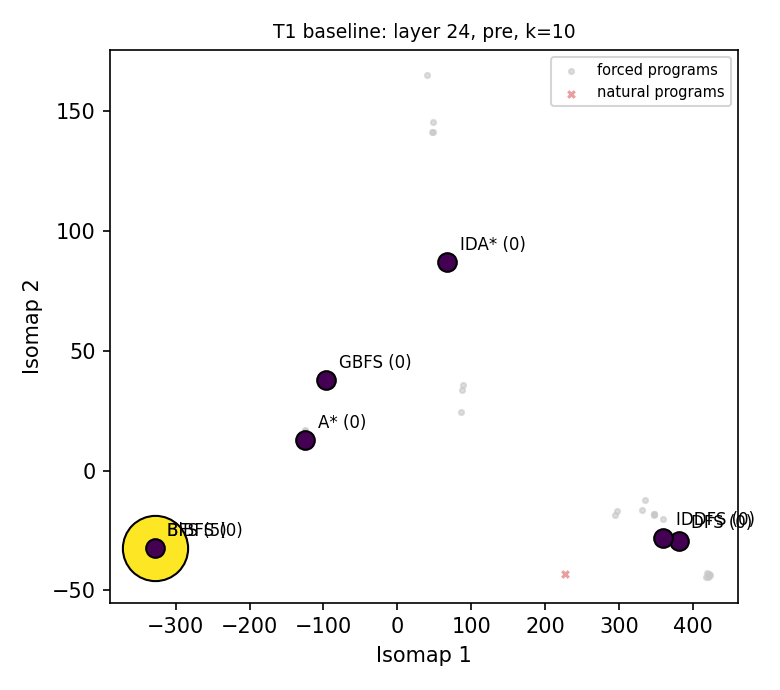

fig_manifold_t1_single_bfs


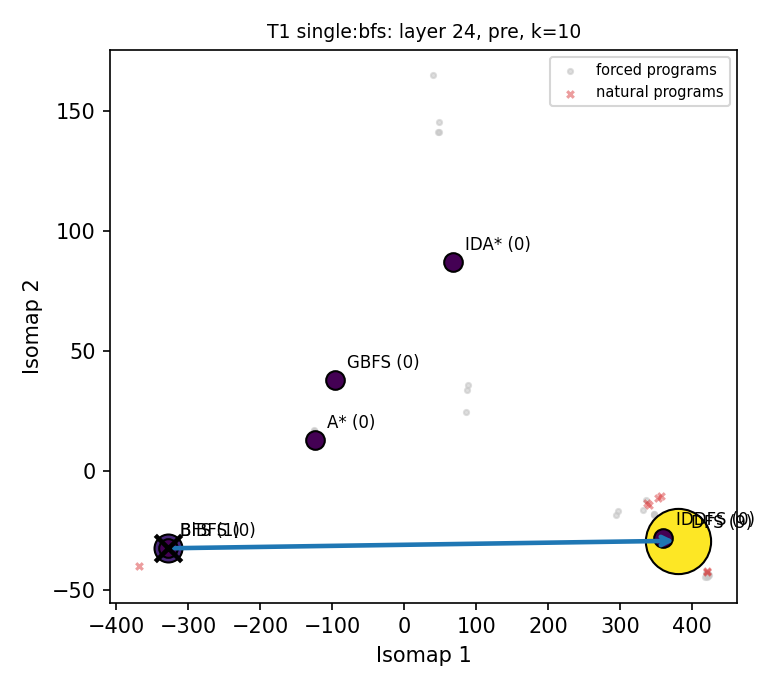

fig_manifold_t1_multi_TOP


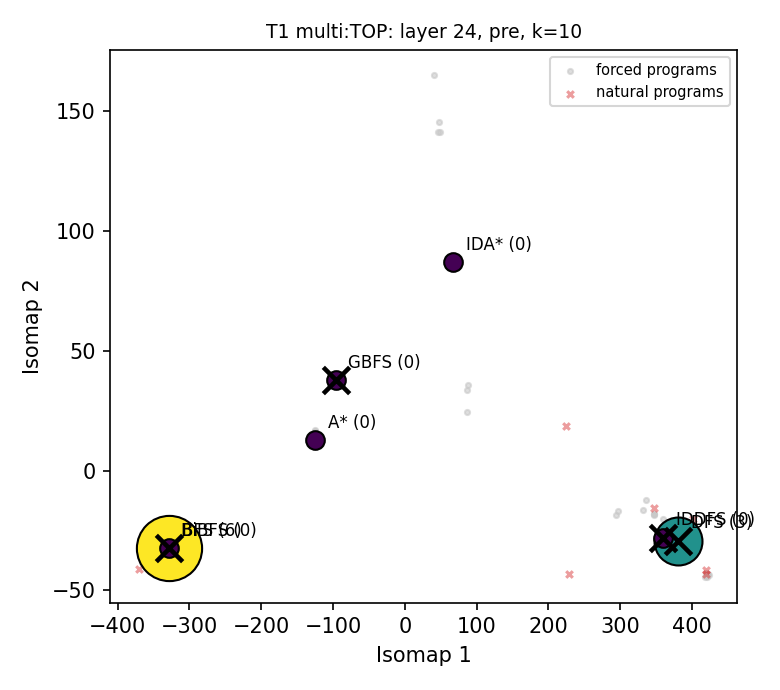

fig_manifold_t1_multi_ARC


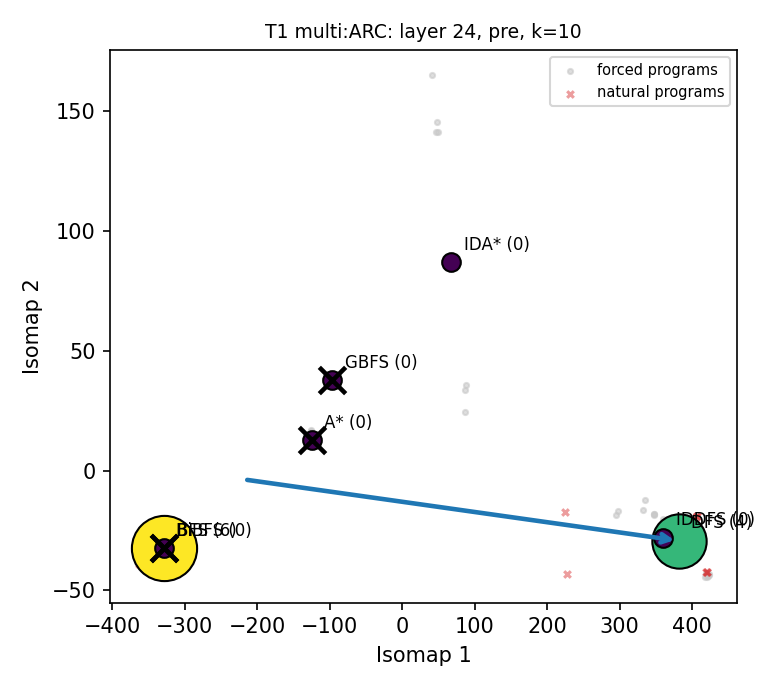

fig_manifold_t1_multi_SCATTER


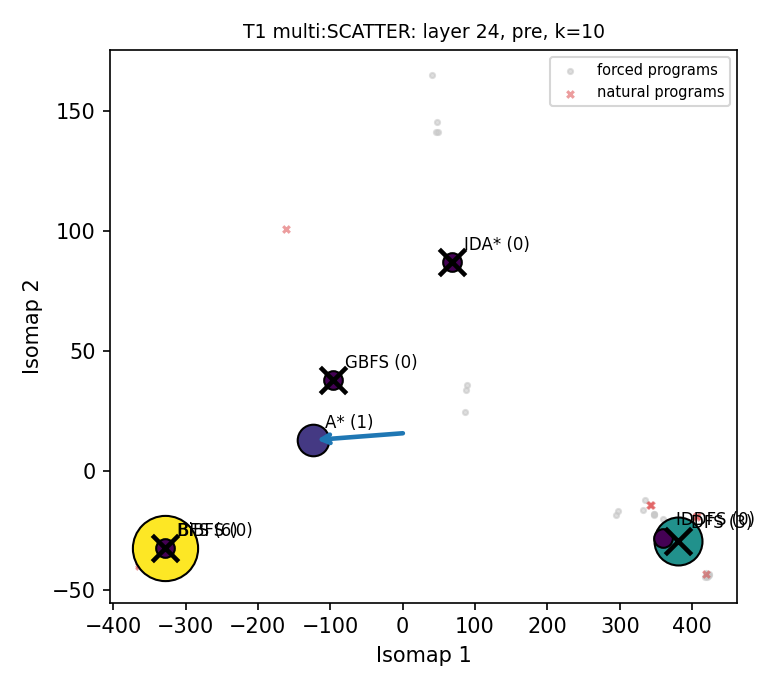

fig_manifold_t1_multi_TOP5


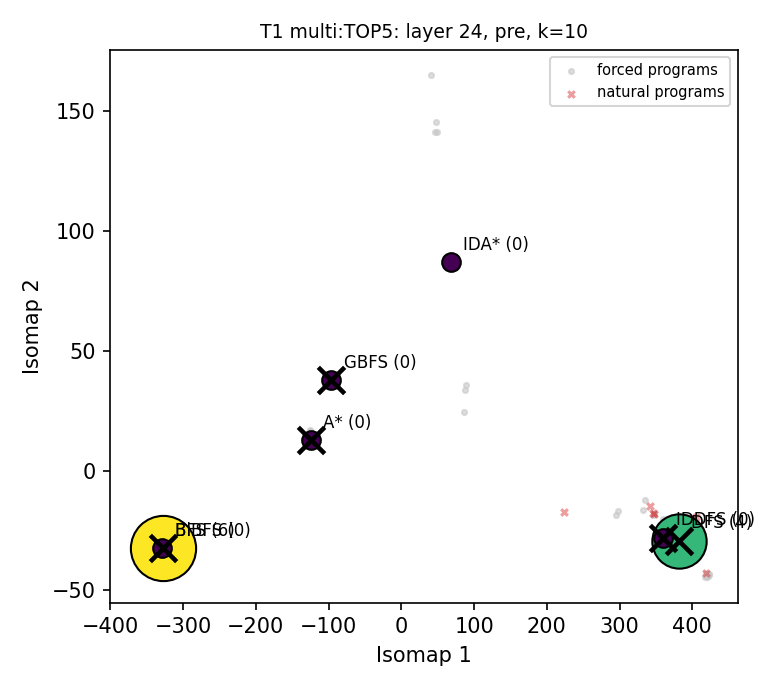

fig_kstab_t1


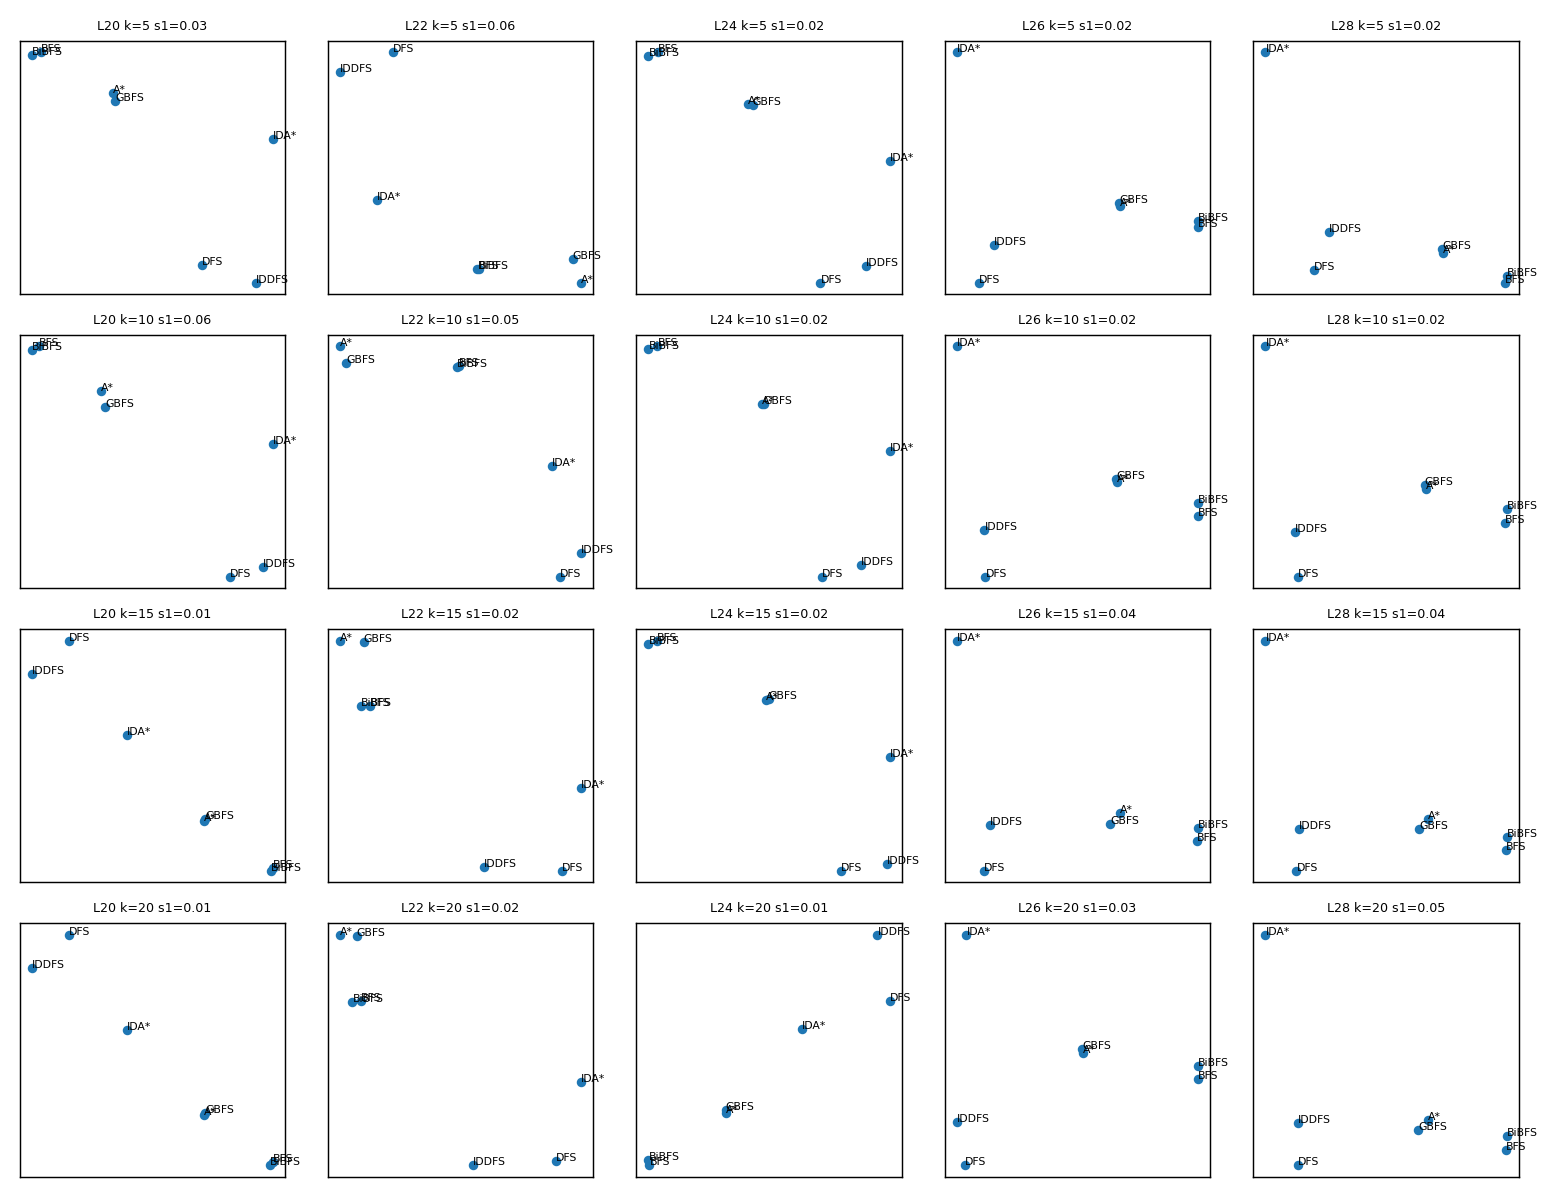

fig_landing


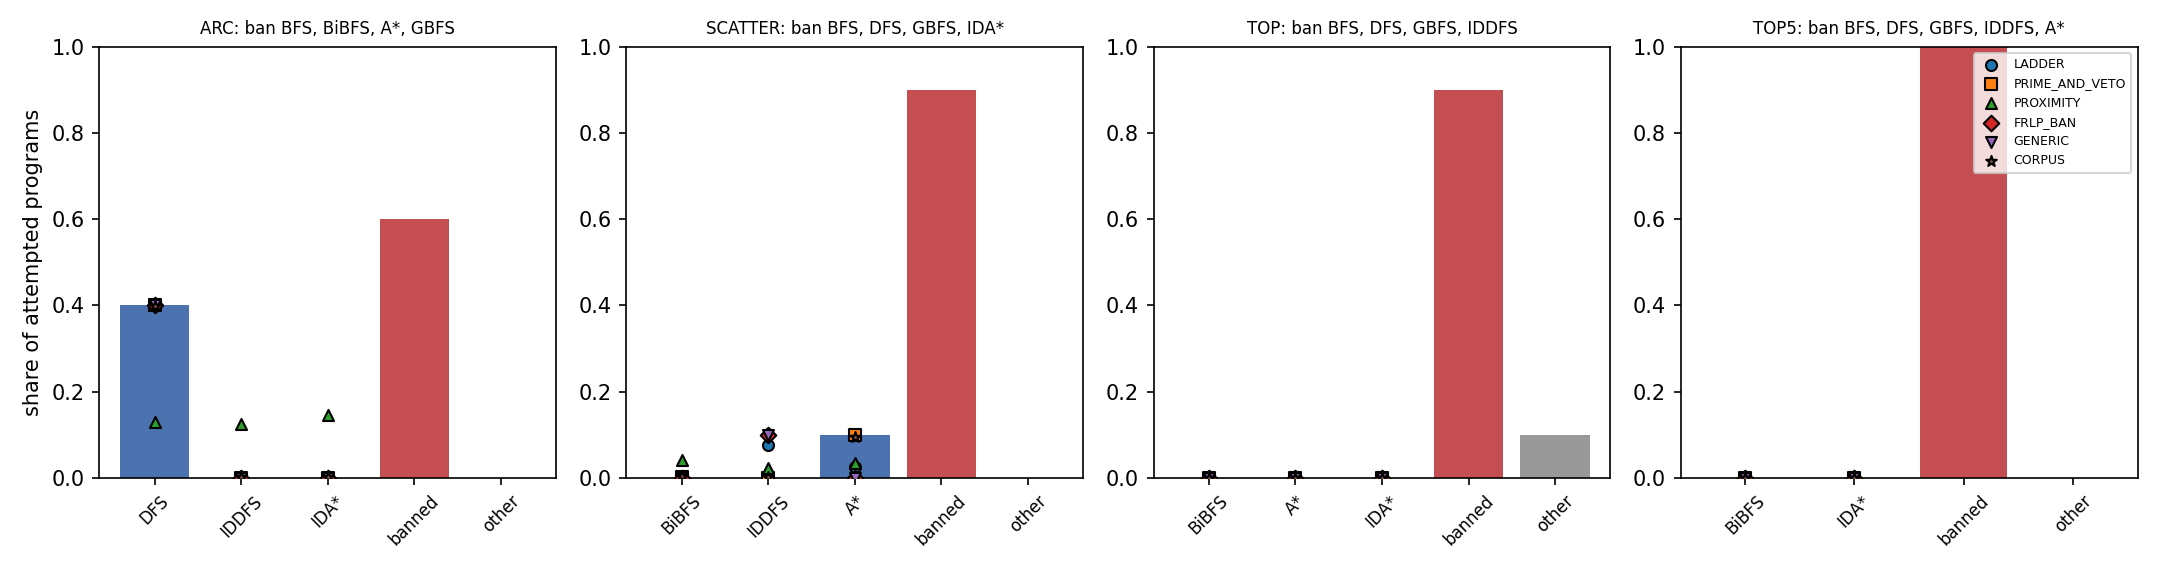

In [27]:
t0 = time.time()
main(["manifold"])
print(f"manifold stage: {time.time() - t0:.1f}s")
man = read_json(RESULTS_DIR / "manifold.json")
mt = man["tasks"]["t1"]
print("primary setting:", man["primary"], "| centroid MDS stress-1:", round(mt["primary_stress1"], 3),
      "| NN stability vs primary:", round(mt["nearest_neighbour_stability_vs_primary"], 2),
      "| bootstrap NN same:", round(mt["bootstrap_nearest_same"], 2))
print("nearest neighbours:", {SHORT[a]: [SHORT[b] for b in v[:2]] for a, v in mt["primary_nearest"].items()})
print("persistence:", read_json(RESULTS_DIR / "persistence.json")["t1"]["verdict"])
for stem in mt["figures"] + ["fig_landing"]:
    p = FIG_DIR / f"{stem}.png"
    if p.exists():
        print(stem)
        display(Image(filename=str(p), width=520))

## 9. Results: demo subset next to the full run

The demo numbers come from the 100-program subset (5-10 programs per condition), so they are noisy. The full-run
numbers (N = 100 per condition, 182 forced programs, 9 layers) are the artifact's reported results, shipped in
`mini_demo_data.json -> metadata.full_run_reference`.

1) Avoidance of the banned mechanisms (gate: avoidance >= 0.5 and >= 20 non-banned programs)
                                                    -- demo --   ------------------- full run -------------------    
condition         banned                              n  avoid         n  avoid  95% CI      gate   disguise  FRLP-implied (committed)
t1|baseline       none                                5   1.00       100   1.00  0.96-1.00   True        n/a  n/a
t1|single:bfs     BFS                                10   0.90       100   0.86  0.78-0.91   True       1.00  n/a
t1|multi:TOP      BFS, DFS, GBFS, IDDFS              10   0.10       100   0.13  0.08-0.21   False      0.51  0.000
t1|multi:ARC      BFS, BiBFS, A*, GBFS               10   0.40       100   0.37  0.28-0.47   False      0.92  0.999
t1|multi:SCATTER  BFS, DFS, GBFS, IDA*               10   0.10       100   0.04  0.02-0.10   False      0.51  0.000
t1|multi:TOP5     BFS, DFS, GBFS, IDDFS, A*          10   0.00       100   0.0

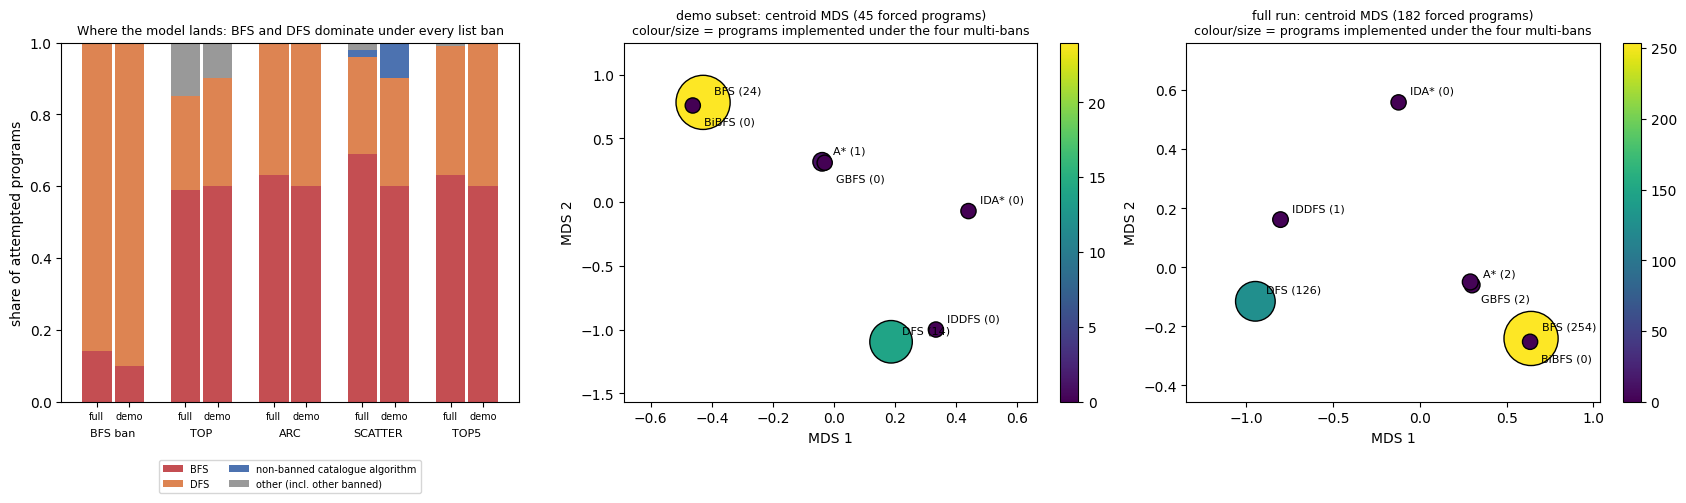

In [28]:
%matplotlib inline
import matplotlib.pyplot as plt

REF = META["full_run_reference"]
CONDS = ["t1|baseline", "t1|single:bfs", "t1|multi:TOP", "t1|multi:ARC", "t1|multi:SCATTER", "t1|multi:TOP5"]
landing = read_json(RESULTS_DIR / "landing.json")
man = read_json(RESULTS_DIR / "manifold.json")["tasks"]["t1"]

print("1) Avoidance of the banned mechanisms (gate: avoidance >= 0.5 and >= 20 non-banned programs)")
print(f"{'':<48}{'-- demo --':>14}   {'------------------- full run -------------------':<52}")
print(f"{'condition':<18}{'banned':<30}{'n':>7}{'avoid':>7}   {'n':>7}{'avoid':>7}  {'95% CI':<12}{'gate':<7}"
      f"{'disguise':>8}  FRLP-implied (committed)")
for key in CONDS:
    d, f = landing["conditions"][key], REF["landing_conditions"][key]
    ci = f["avoidance_ci"]
    print(f"{key:<18}{', '.join(SHORT[b] for b in f['banned']) or 'none':<30}{d['attempted']:>7}{_f(d['avoidance']):>7}   "
          f"{f['attempted']:>7}{_f(f['avoidance']):>7}  {(_f(ci[0]) + '-' + _f(ci[1])) if ci else 'n/a':<12}"
          f"{str(f['gate']):<7}{_f(f['disguise_rate']):>8}  {_f(f.get('frlp_implied_avoidance'), 3)}")

print("\n2) Per-row predictors: share of programs whose mechanism equals the predictor's top-1")
acc = collections.defaultdict(list)
for ex in EXAMPLES:
    c = ex["metadata_condition"]
    g = "forced" if c.startswith("forced") else c.split(":")[0]
    for k, v in ex.items():
        if k.startswith("predict_"):
            acc[f"{g}|{k}"].append(v == ex["output"])
full_acc = REF["predictor_accuracy"]["per_row_top1_accuracy"]
for k in sorted(acc):
    print(f"   {k:<28} demo {np.mean(acc[k]):.2f} (n={len(acc[k]):>2})   full {full_acc.get(k, float('nan')):.3f}")
print("   (the demo's forced programs come from the scored program sets, which hold only programs labelled as\n"
      "    requested, so forced|predict_requested is 1.00 by construction there)")

print("\n3) BFS share among BFS+DFS programs under the four multi-bans (post hoc homogeneity test, full run: "
      f"chi-square p = {REF['posthoc_mix_homogeneity']['chi2_p']:.2f})")
for s, (b, d) in REF["posthoc_mix_homogeneity"]["bfs_dfs_counts"].items():
    dc = landing["conditions"][f"t1|multi:{s}"]["fine_labels"]
    nb, nd = dc.get("bfs", 0), dc.get("dfs", 0)
    print(f"   {s:<8} full {b / (b + d):.2f} (BFS {b}, DFS {d})   demo {nb / max(nb + nd, 1):.2f} (BFS {nb}, DFS {nd})")

print("\n4) Activation geometry (layer 24, position pre, k = 10)")
print(f"   centroid MDS stress-1: demo {man['primary_stress1']:.3f}   full {REF['manifold_t1']['primary_stress1']:.3f}")
for a in man["algorithms"]:
    print(f"   {SHORT[a]:<7} nearest  demo {[SHORT[b] for b in man['primary_nearest'][a][:2]]!s:<22}"
          f" full {[SHORT[b] for b in REF['manifold_t1']['primary_nearest'][a][:2]]}")
pd_, pf = read_json(RESULTS_DIR / "persistence.json")["t1"], REF["persistence_t1"]
print(f"   persistent H1: demo '{pd_['verdict']}' (p_shuffle {pd_['centroid_bootstrap']['p']:.2f}), "
      f"full '{pf['verdict']}' (p_shuffle {pf['centroid_bootstrap']['p']:.2f})")
print("   within-ban probes, full run (balanced accuracy at layer 24; label-shuffle p):")
for k, v in REF["within_ban_internals_t1"].items():
    print(f"     {k:<18} classes {v['classes']}  " + "  ".join(
        f"{pos}: {v['null'][pos]['observed']:.2f} (p={v['null'][pos]['p']:.2f})" for pos in ("R", "g16", "pre")))
print("     (R = last prompt token, a negative control. g16 = 16th generated token, label-independent: near chance.\n"
      "      'pre' sits just before the first mechanism-revealing token, so its position depends on the label and the\n"
      "      'pre' probes leak the label: deviation D-pre-leak, not evidence of a plan)")

# ---- figure: landing per condition (demo vs full) and the centroid geometry in activation space
cats = ["bfs", "dfs", "survivor", "other"]
colors = {"bfs": "#c44e52", "dfs": "#dd8452", "survivor": "#4c72b0", "other": "#999999"}

def shares(counts: dict[str, int], banned: list[str]) -> dict[str, float]:
    n = max(sum(counts.values()), 1)
    out = {"bfs": 0, "dfs": 0, "survivor": 0, "other": 0}
    for k, v in counts.items():
        lab = k.split(":", 1)[1] if k.startswith("banned:") else k
        out[lab if lab in ("bfs", "dfs") else "other" if lab == "other" or k.startswith("banned:") else "survivor"] += v
    return {k: v / n for k, v in out.items()}

fig, axes = plt.subplots(1, 3, figsize=(17, 5.2))
ax = axes[0]
xt, xl = [], []
for i, key in enumerate(CONDS[1:]):
    for j, (lab, src) in enumerate((("full", REF["landing_conditions"][key]), ("demo", landing["conditions"][key]))):
        sh = shares(src["counts"], src["banned"])
        x, bottom = i * 3.0 + j * 1.1, 0.0
        for c in cats:
            ax.bar(x, sh[c], bottom=bottom, color=colors[c], width=1.0, label=c if (i, j) == (0, 0) else None)
            bottom += sh[c]
        xt.append(x)
        xl.append(lab)
    ax.text(i * 3.0 + 0.55, -0.075, key.split('|')[1].replace('multi:', '').replace('single:bfs', 'BFS ban'),
            transform=ax.get_xaxis_transform(), ha="center", va="top", fontsize=8)
ax.set_xticks(xt)
ax.set_xticklabels(xl, fontsize=7)
ax.set_ylabel("share of attempted programs")
ax.set_title("Where the model lands: BFS and DFS dominate under every list ban", fontsize=9)
ax.legend(["BFS", "DFS", "non-banned catalogue algorithm", "other (incl. other banned)"], fontsize=7,
          loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=2)

implemented = collections.Counter(ex["output"] for ex in EXAMPLES if ex["metadata_condition"].startswith("multi:"))
implemented_full = collections.Counter()
for key in CONDS[2:]:
    for k, v in REF["landing_conditions"][key]["counts"].items():
        implemented_full[k.split(":", 1)[1] if k.startswith("banned:") else k] += v
for ax, (title, mds, cnt) in zip(axes[1:], (("demo subset: centroid MDS (45 forced programs)", man["primary_mds"], implemented),
                                            ("full run: centroid MDS (182 forced programs)", REF["manifold_t1"]["primary_mds"], implemented_full))):
    Z = np.array([mds[a] for a in man["algorithms"]])
    nmax = max(max(cnt.values()), 1)
    sc = ax.scatter(Z[:, 0], Z[:, 1], s=[120 + 1400 * cnt.get(a, 0) / nmax for a in man["algorithms"]],
                    c=[cnt.get(a, 0) for a in man["algorithms"]], cmap="viridis", edgecolor="k", vmin=0, vmax=nmax)
    placed = []
    for a, z in zip(man["algorithms"], Z):
        close = any(np.linalg.norm(z - q) < 0.06 * np.ptp(Z[:, 0]) for q in placed)  # stack labels of near-twins
        ax.annotate(f"{SHORT[a]} ({cnt.get(a, 0)})", z, xytext=(8, -14 if close else 6), textcoords="offset points",
                    fontsize=8)
        placed.append(z)
    ax.set_title(title + "\ncolour/size = programs implemented under the four multi-bans", fontsize=9)
    ax.set_xlabel("MDS 1")
    ax.set_ylabel("MDS 2")
    ax.margins(0.25)
    plt.colorbar(sc, ax=ax, fraction=0.046)
fig.tight_layout()
plt.show()

**Reading the results.**

- **Reproduced exactly from the shipped inputs:**
  - all 100 mechanism labels (extraction, AST rules and combine rule);
  - all committed landing forecasts and FRLP-implied avoidances (difference 0.0);
  - the TOP / ARC / SCATTER / TOP5 sets, from the full-run geodesic matrix;
  - every shipped payload hash of the commitment chain.
- **Behaviour.** A single ban moves the model off BFS (to DFS 86%). Four or five names in one prompt do not: the
  model writes the banned BFS or DFS anyway, in about the same BFS/DFS mix (about 2:1) whichever list is used. The
  likelihood forecasts committed before sampling put this failure at < 1e-8 avoidance for TOP, SCATTER and TOP5. For
  ARC they were over-optimistic (0.999 forecast against 0.37 realised).
- **Geometry.** The 45 forced programs of the subset reproduce the full run's neighbour structure in activation space
  (BFS next to BiBFS, DFS next to IDDFS, A* next to greedy), and the centroid MDS stress-1 stays low (about 0.02-0.03).
  Neither the demo nor the full run shows a persistent loop. With 6-7 programs per algorithm, the ARC and SCATTER sets
  re-selected from the demo matrix differ from the committed ones: set selection needs the full program sets.
- **Not run here:** vLLM sampling, teacher-forced scoring, the runtime tracer and the judge (GPU / API), the within-ban
  probes (`own`-context states) and the T2 leave-one-survivor analysis (the T2 dataset).